# **Прикладные задачи МО на графах. 29.10.2025**

Библиотека для работы с графами [NetworkX](https://networkx.org/documentation/stable/)

# Graph Neural Network

Задача - найти такое представление графа, которое бы отражало графовую структуру, для последующего решения задач машинного обучения (классификации, кластеризации, предсказания каких-либо свойств и т.п.).

GNN_schema.svg

* Граф $G = (V, E)$
* Матрица смежности $A \in \mathbb{R}^{\vert V \vert \times \vert V \vert}$
* Матрица $X$, содержащая признаки узлов,  $X \in \mathbb{R}^{\vert V \vert \times m}$.
* Получить для каждого узла графа вектор $z \in \mathbb{R}^d$ такой, что $d \ll \vert V \vert$.

## Графовая свертка

Графовая свертка — концепт, абстрактная операция обновляющая скрытые представления вершин (ребер, подграфов). Идея взята из светочных нейронных сетей (convolutional neural networks, CNNs).

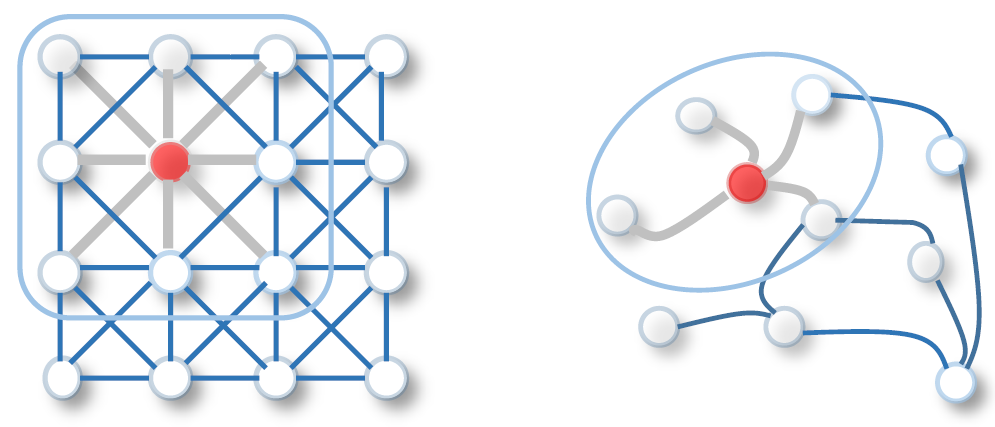

Общий принцип работы отражен в алгоритме 1, взятом из [Representation Learning on Graphs: Methods and Applications](https://arxiv.org/abs/1709.05584).

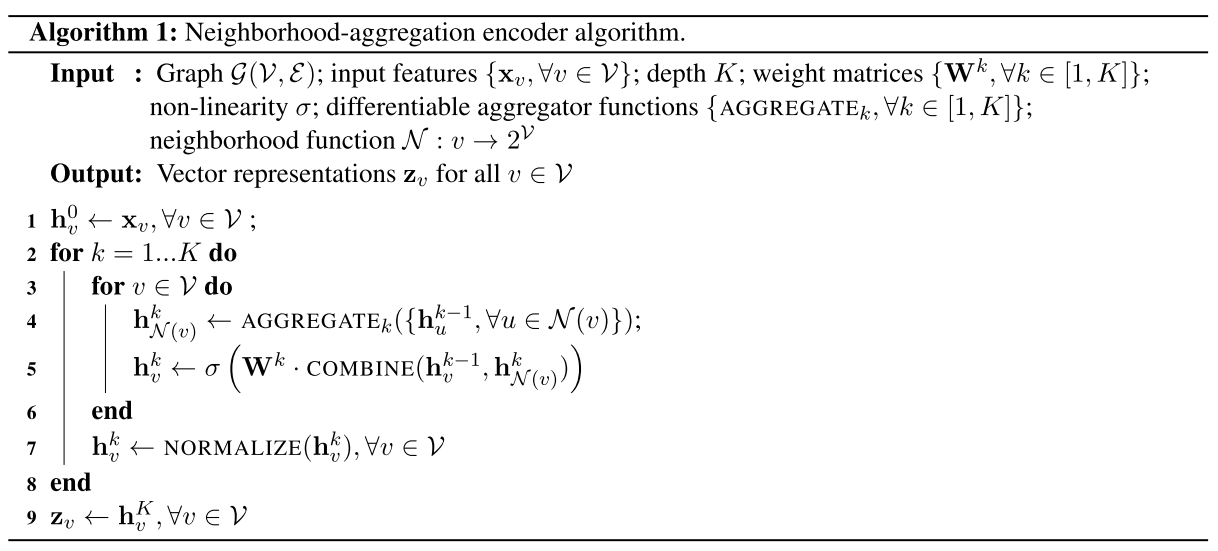

* Алгоритм строит эмбеддинги для узлов рекурсивно.
* Начальное состояние — атрибуты узлов (если они есть).
* На каждой итерации агрегируются эмбеддинги соседей (строка 4).
* Каждый узел получает новые эмбеддинги, скомбинированные из ее
собственного вектора эмбеддингов и агрегированного вектора (строка 5).
* Затем все это отправляется в полносвязный слой и процесс
повторяется $K$ раз.
* Вектор признаков для каждого узла обогащается данными соседей
* Размерность остается постоянной.

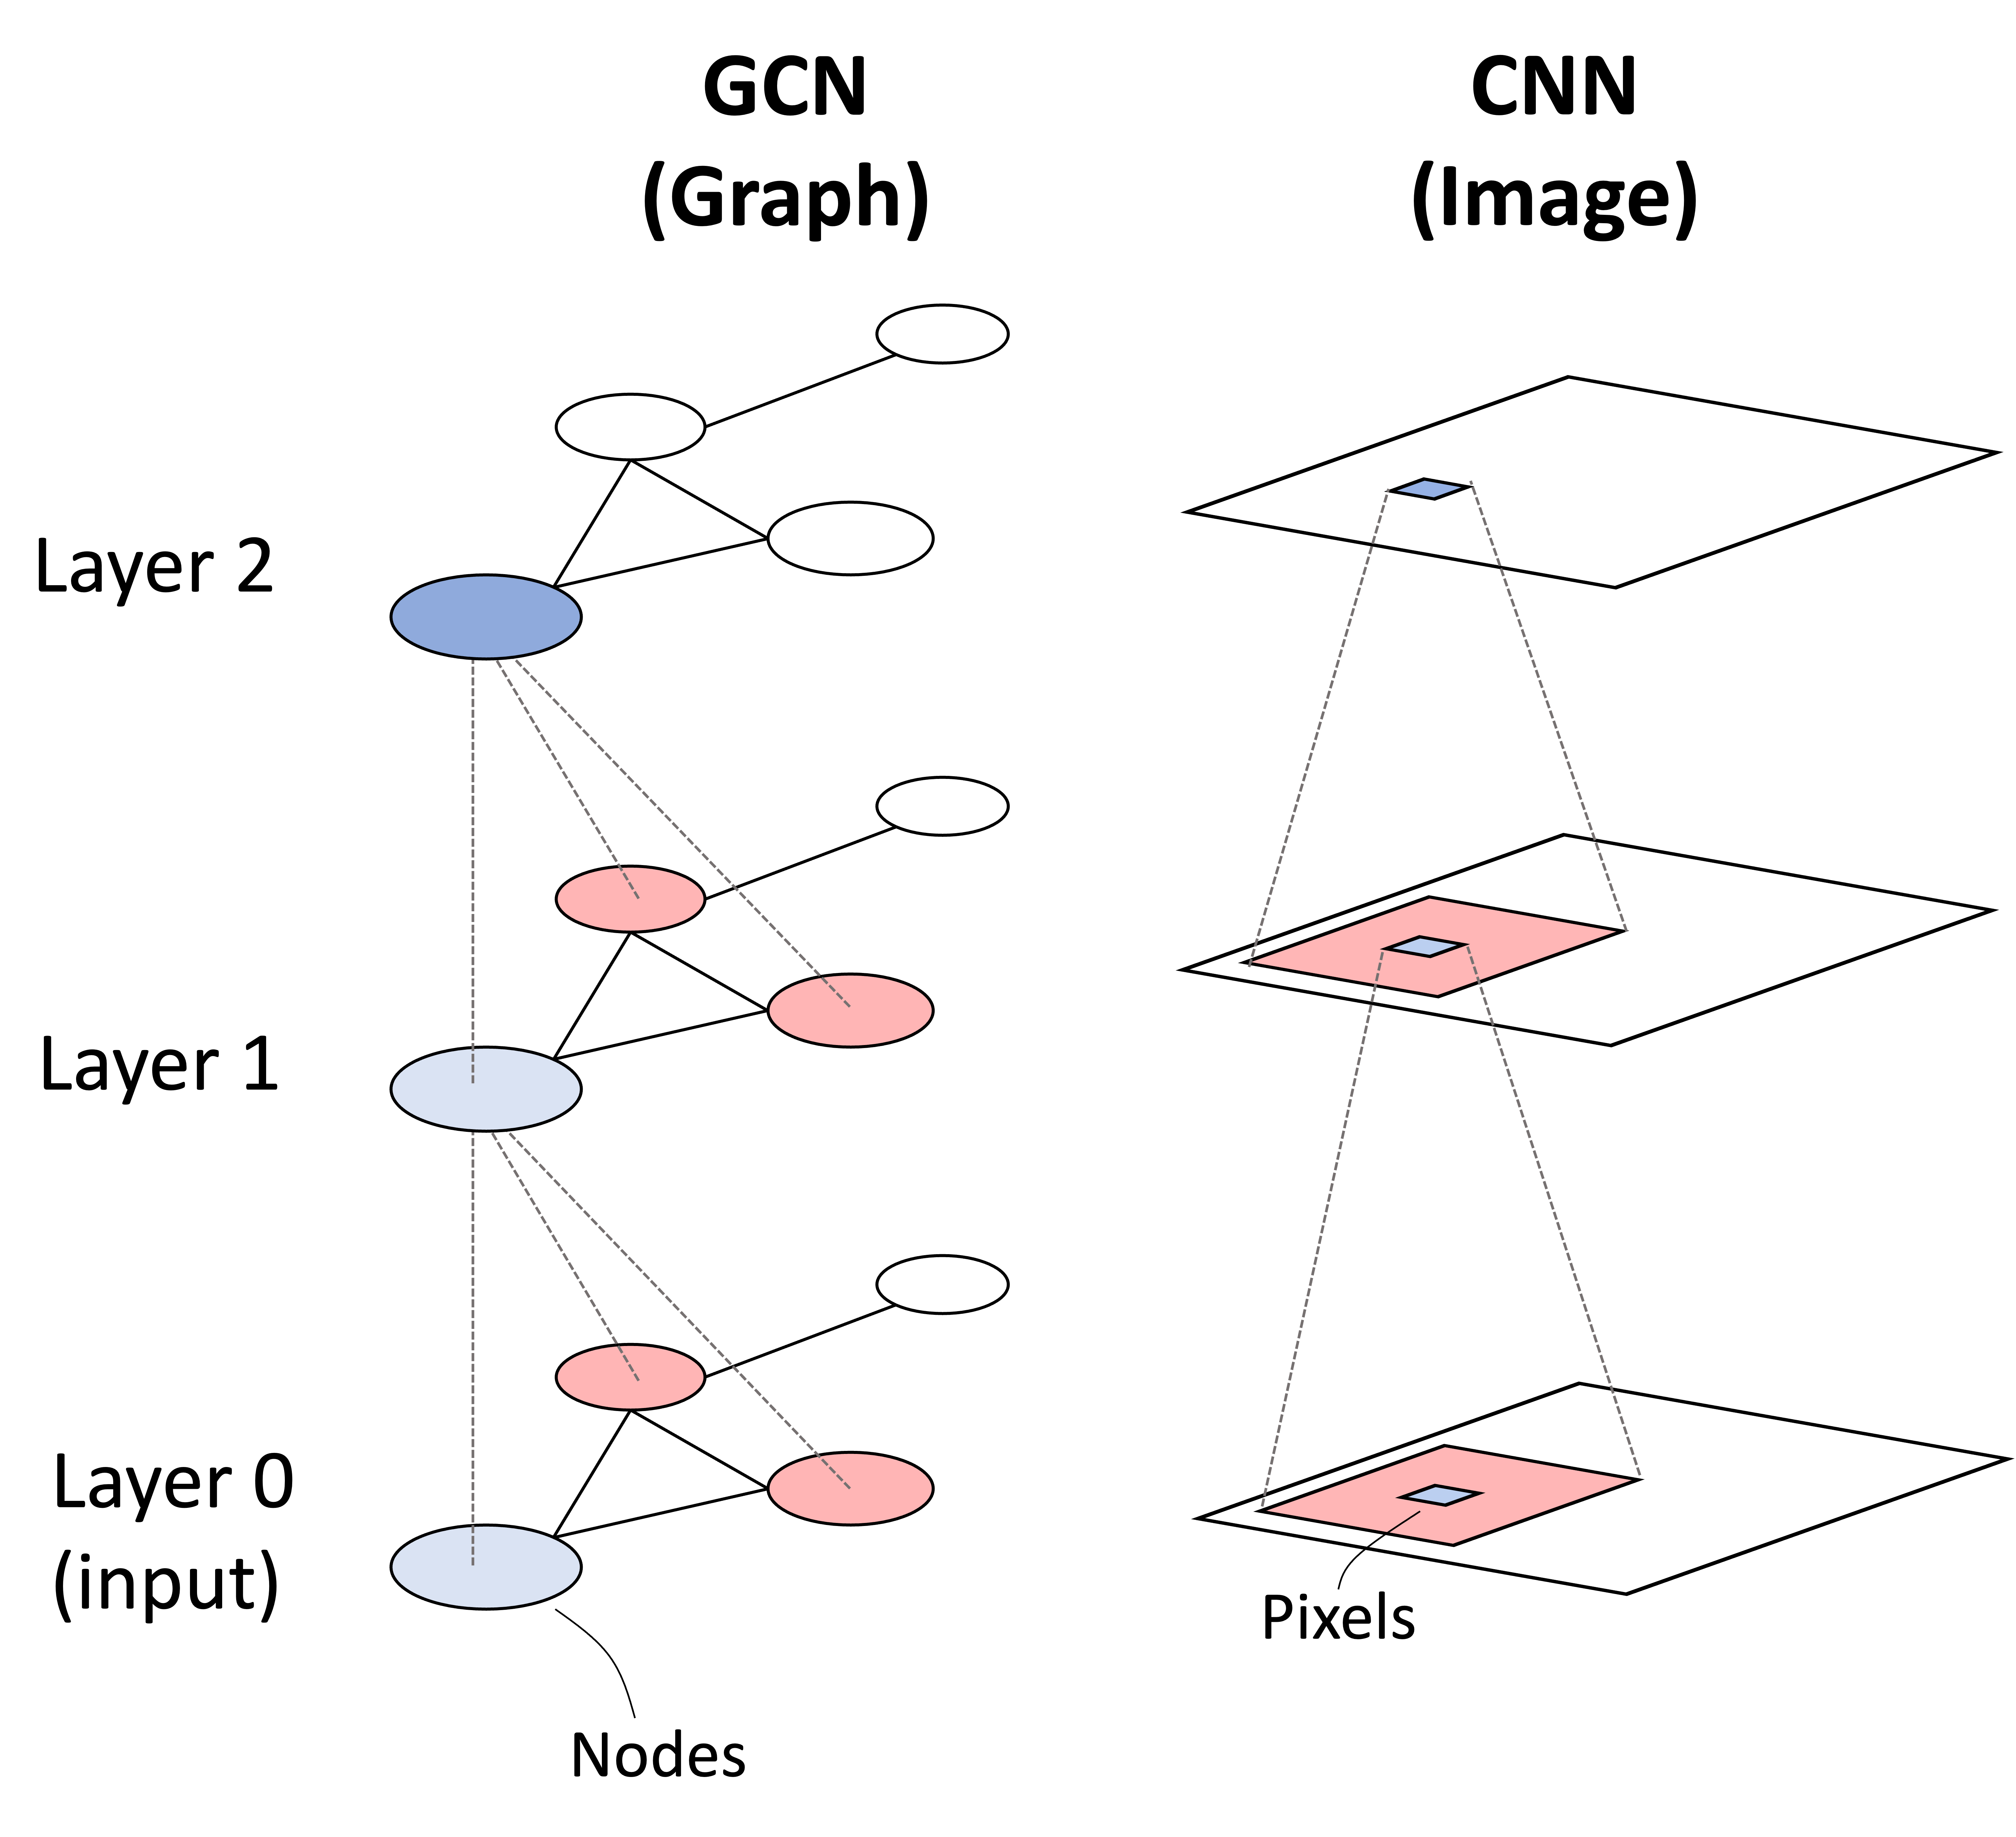

# GCN (Graph Convolutional Networks)

Рассмотрим GCN так, как это изложено в работе  [Kipf and Welling (2017)](https://arxiv.org/abs/1609.02907).
CGN принимает на вход граф с некоторыми атрибутами для каждого узла (атрибутов может не быть). После ряда преобразований получаем новый вектор-признаков для каждого узла (обычно меньшего размера).

Для задач на уровне узлов (node-level tasks), классификация узлов, например, может проводиться по полученному финальному вектору-признаков.

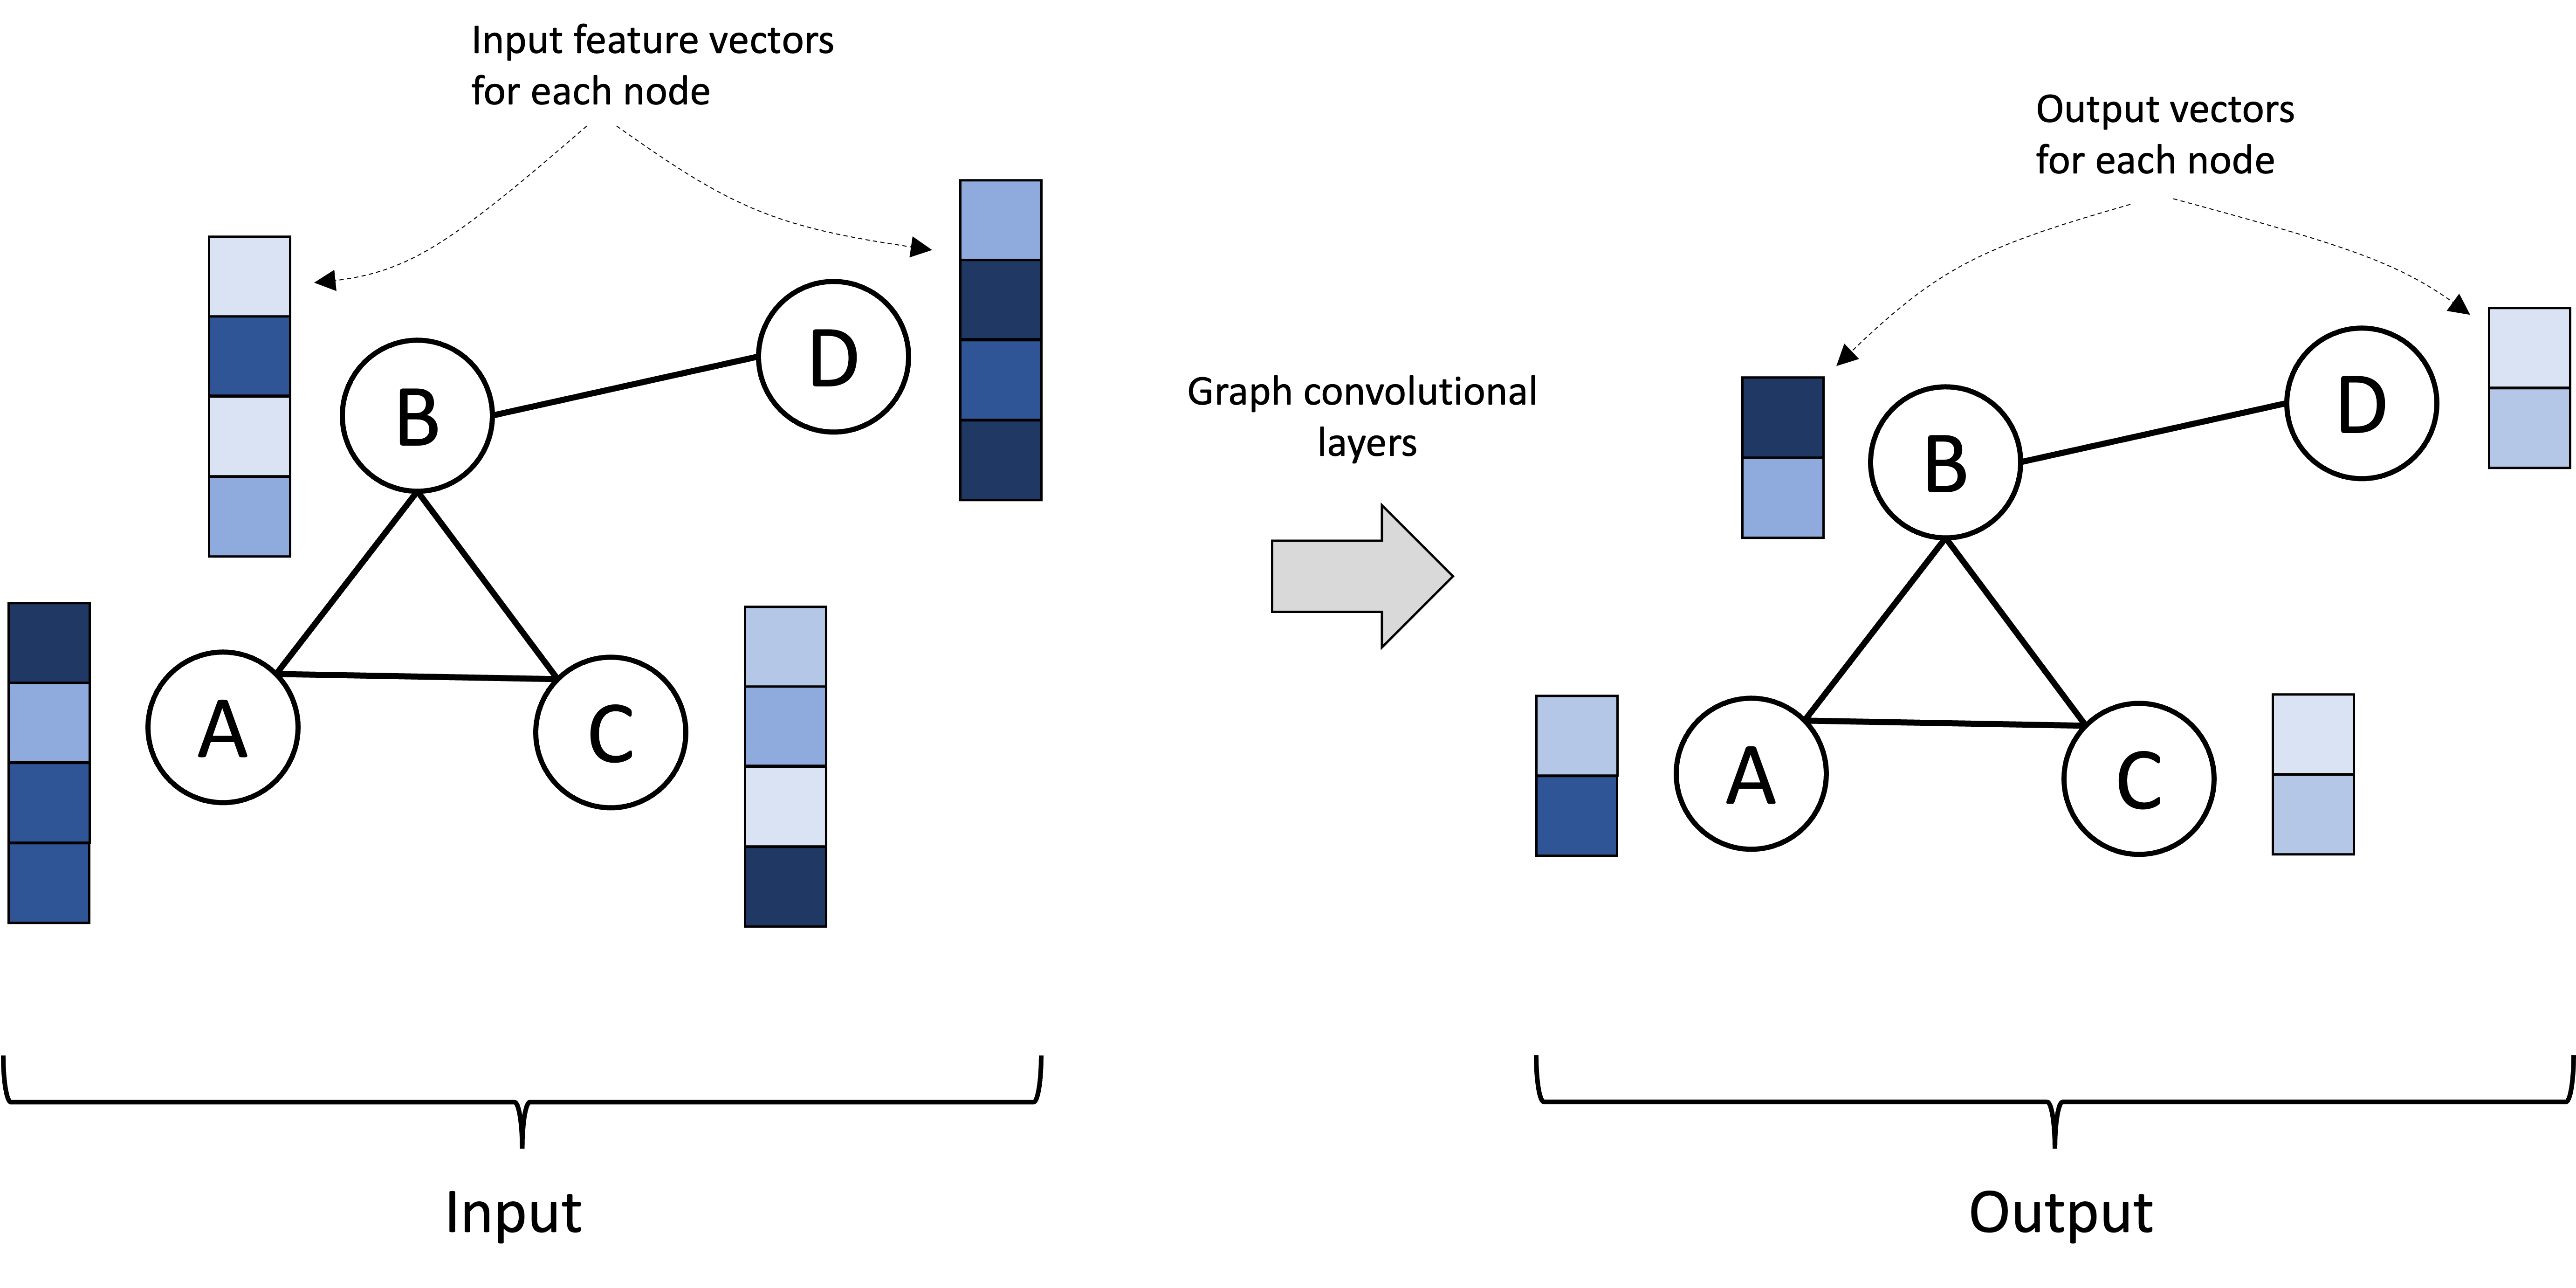

Для задач уровне графов (graph-level) полученные признаки для вершин можно использовать, как начальные, для некоторой другой нейронной сети (например,полносвязной) для решения задачи классификации графов.

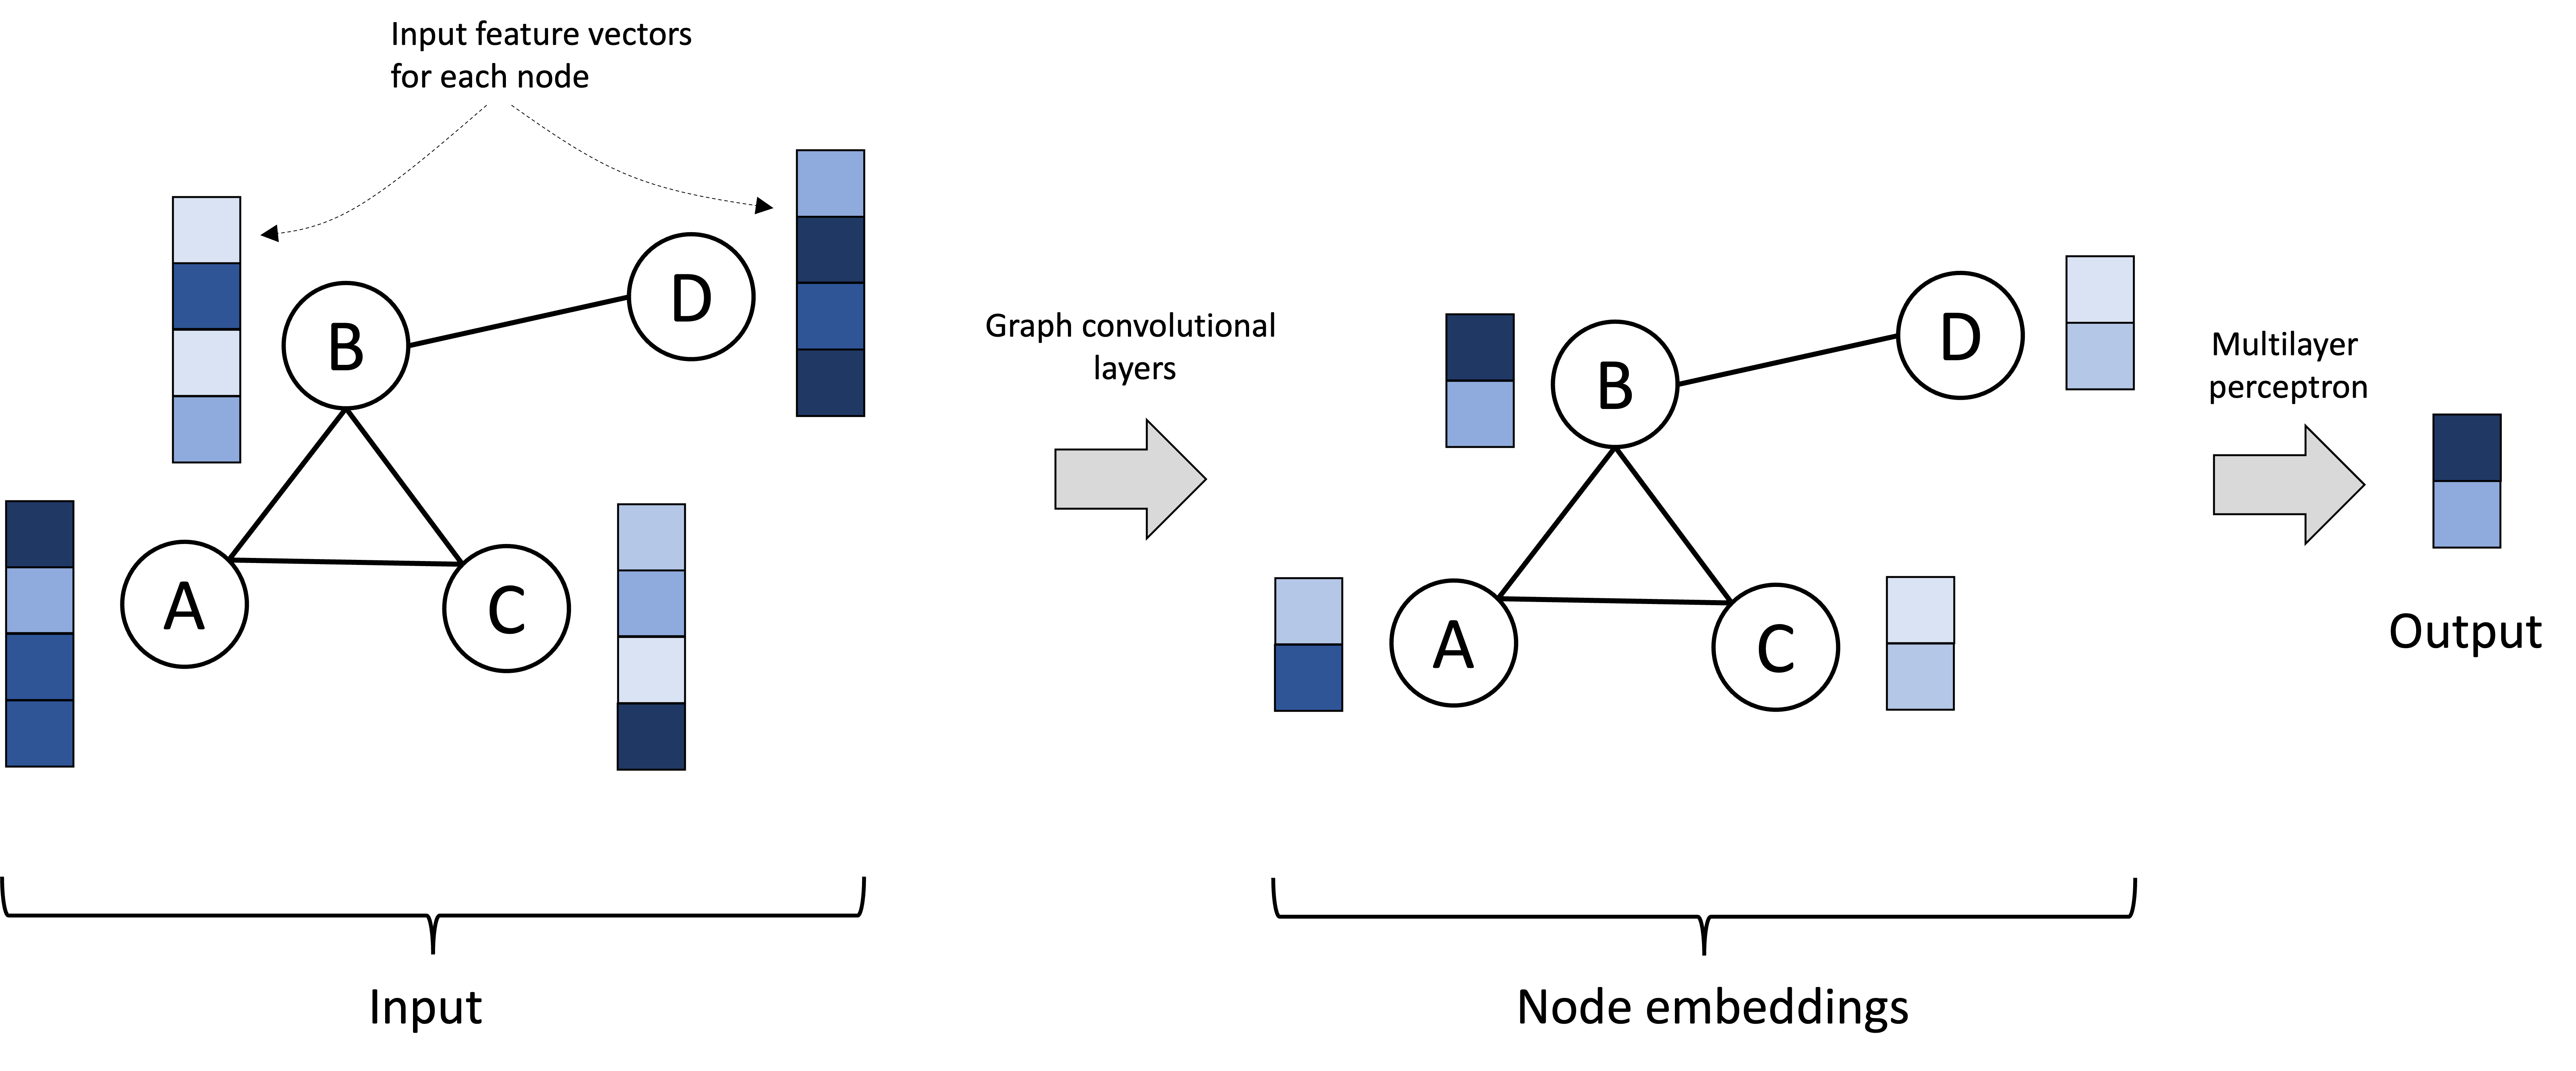

## Слой GCN

**Message passing**

На уровне слоя GCN каждая вершина получает "сообщение" от вершин-соседей.

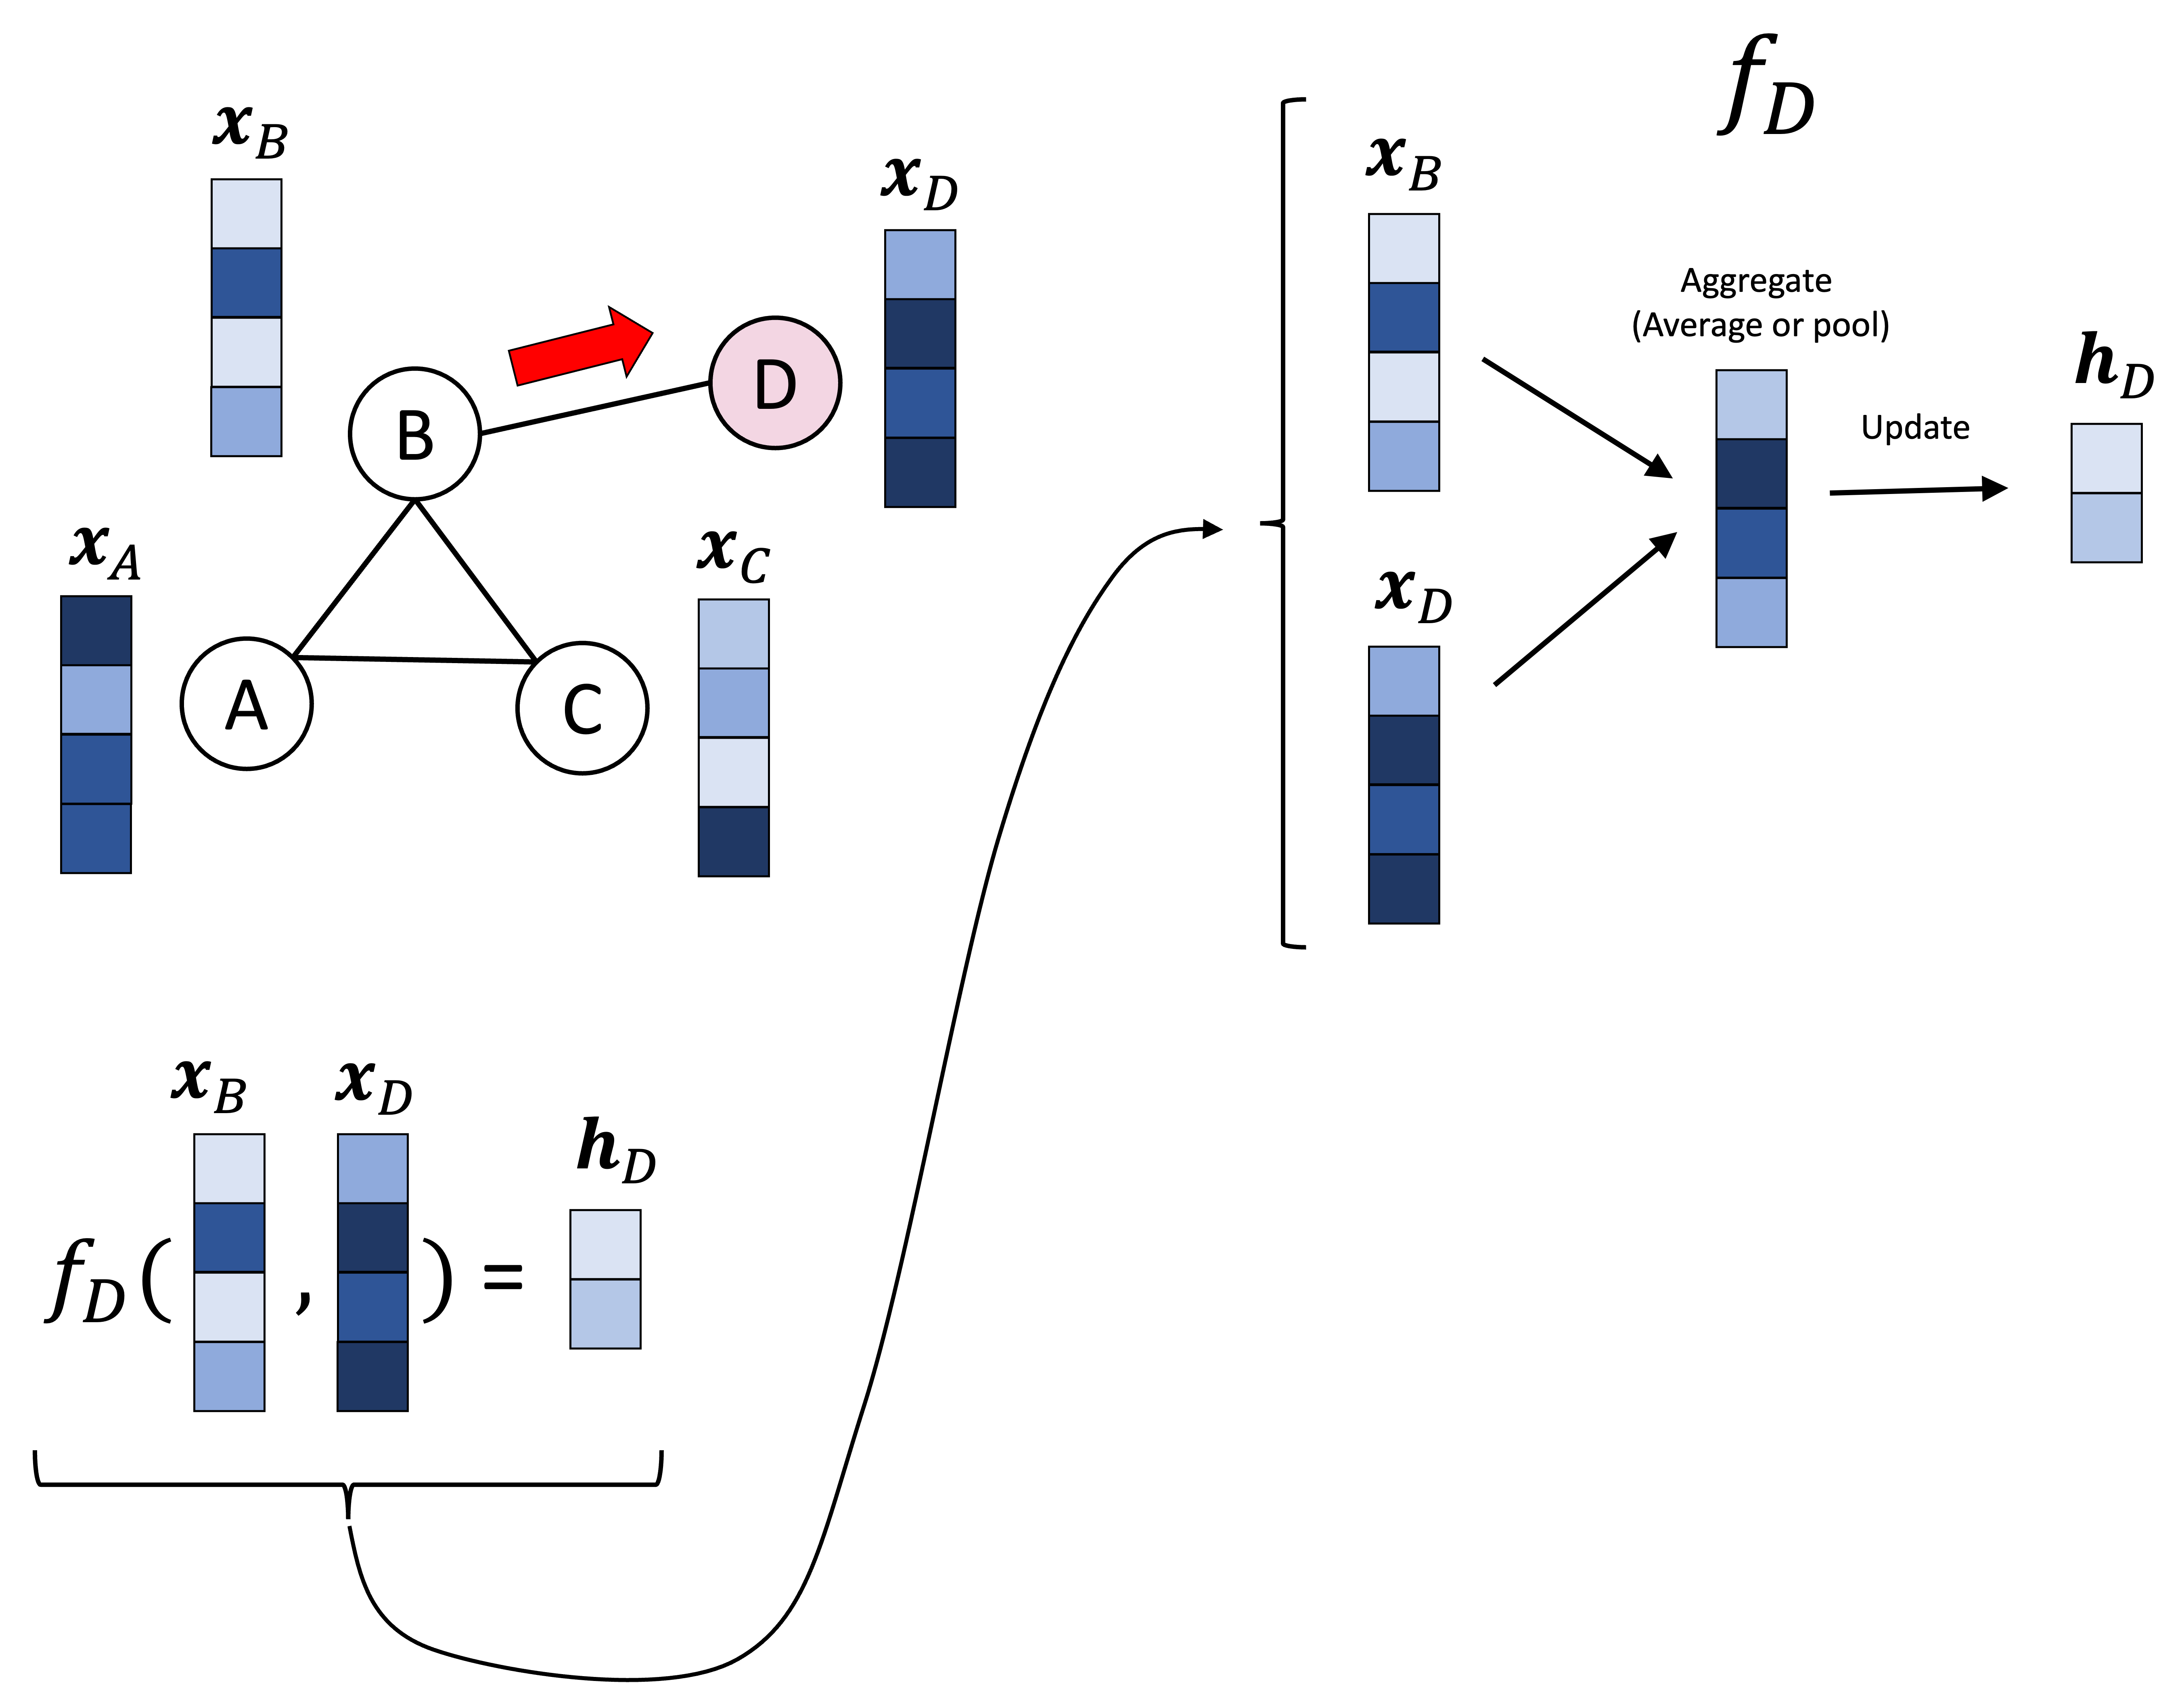

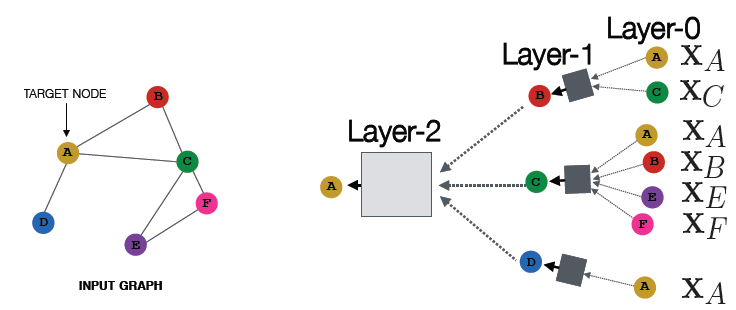

* Слой $0$: вектор признаков узла $x_v$
* Слой $K$: вектор признаков с "сообщениями" от соседей в $K$-окрестности.

* Начальные признаки в $0$-слое: $$h_v^{0} = x_v$$
* Обновления $$ h^{(k+1)}_v = \sigma\left(W_k \sum_{u\in N(v)} \cfrac{h_u^{(k)}}{|N(v)|} + B_k h_{v}^{(k)}\right), \;\; \forall k \in \{0, \ldots, K - 1\}$$
* Эмбеддинги после слоя $K$: $z_v = h_v^{(K)}$
* $\sigma$ - функция активации (например, ReLU)
* $W_k, B_k$ - обучаемые матрицы весов.

* Пусть $H^{(k)} = [h_1^{(k)} \ldots h_{|V|}^{(k)}]^T$.
* Тогда $\sum_{u\in N(v)} h_u^{(k)} = A_{v,:} H^{(k)}$.
* Если $D$ - диагональная матрица степеней с $D_{v,v} = \deg(v) = |N(v)|$, то  
$$\sum_{u\in N(v)} \cfrac{h_u^{(k)}}{|N(v)|} \;\; \Rightarrow \;\; H^{(k+1)} = D^{-1} A H^{(k)}.$$
* В матричном виде скрытые представления можно записать
$$H^{(k+1)} = \sigma(\hat{A}H^{(k)} W_k^{T} + H^{(k)} B_k^T),$$ где $\hat{A} = D^{-1}A$.

Собираем "сообщения" от соседей

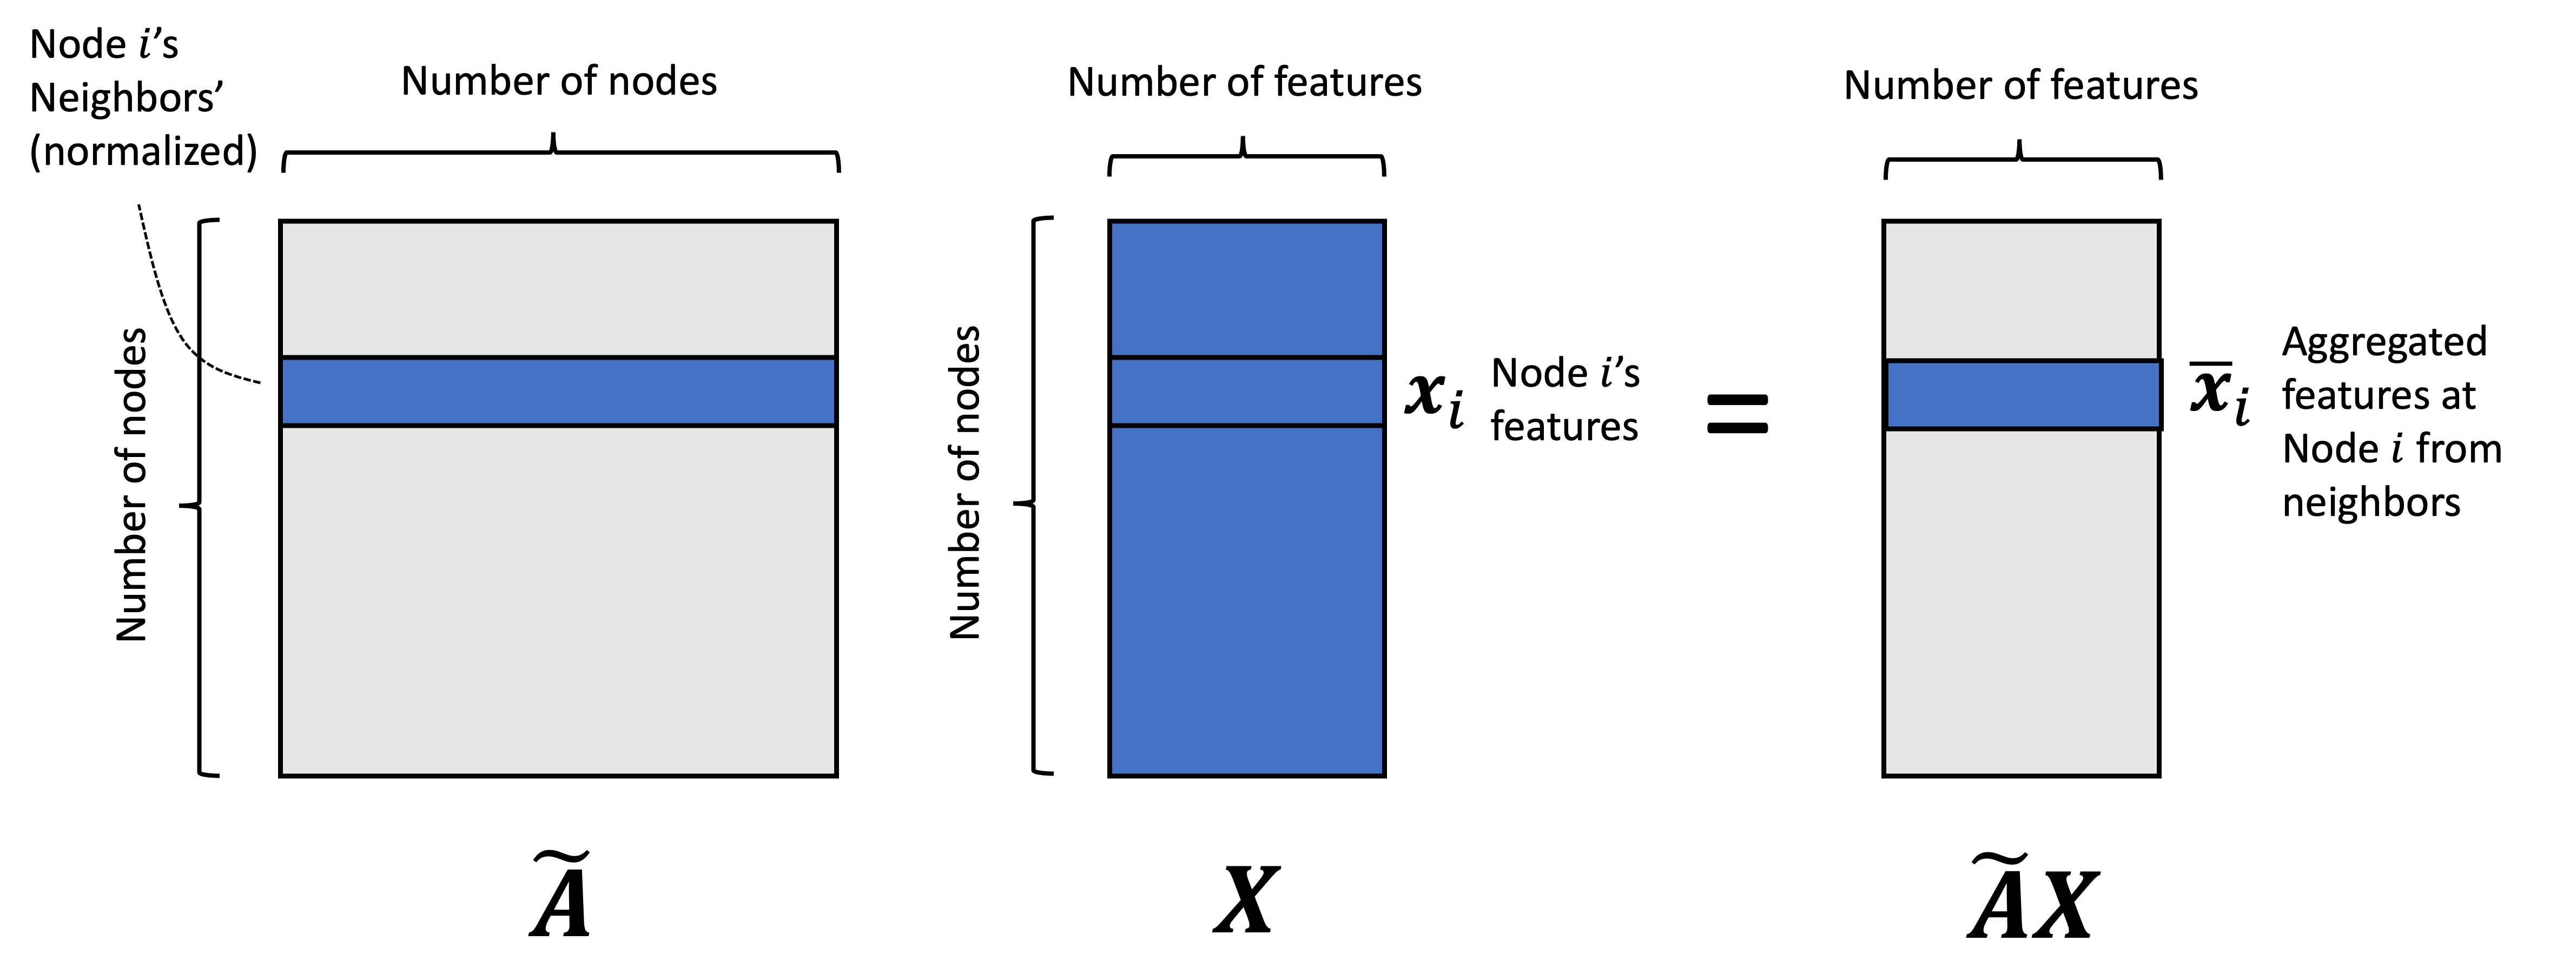

Домножаем на веса, т.е. учитываем "влияние" соседей, и получаем новый вектор признаков.

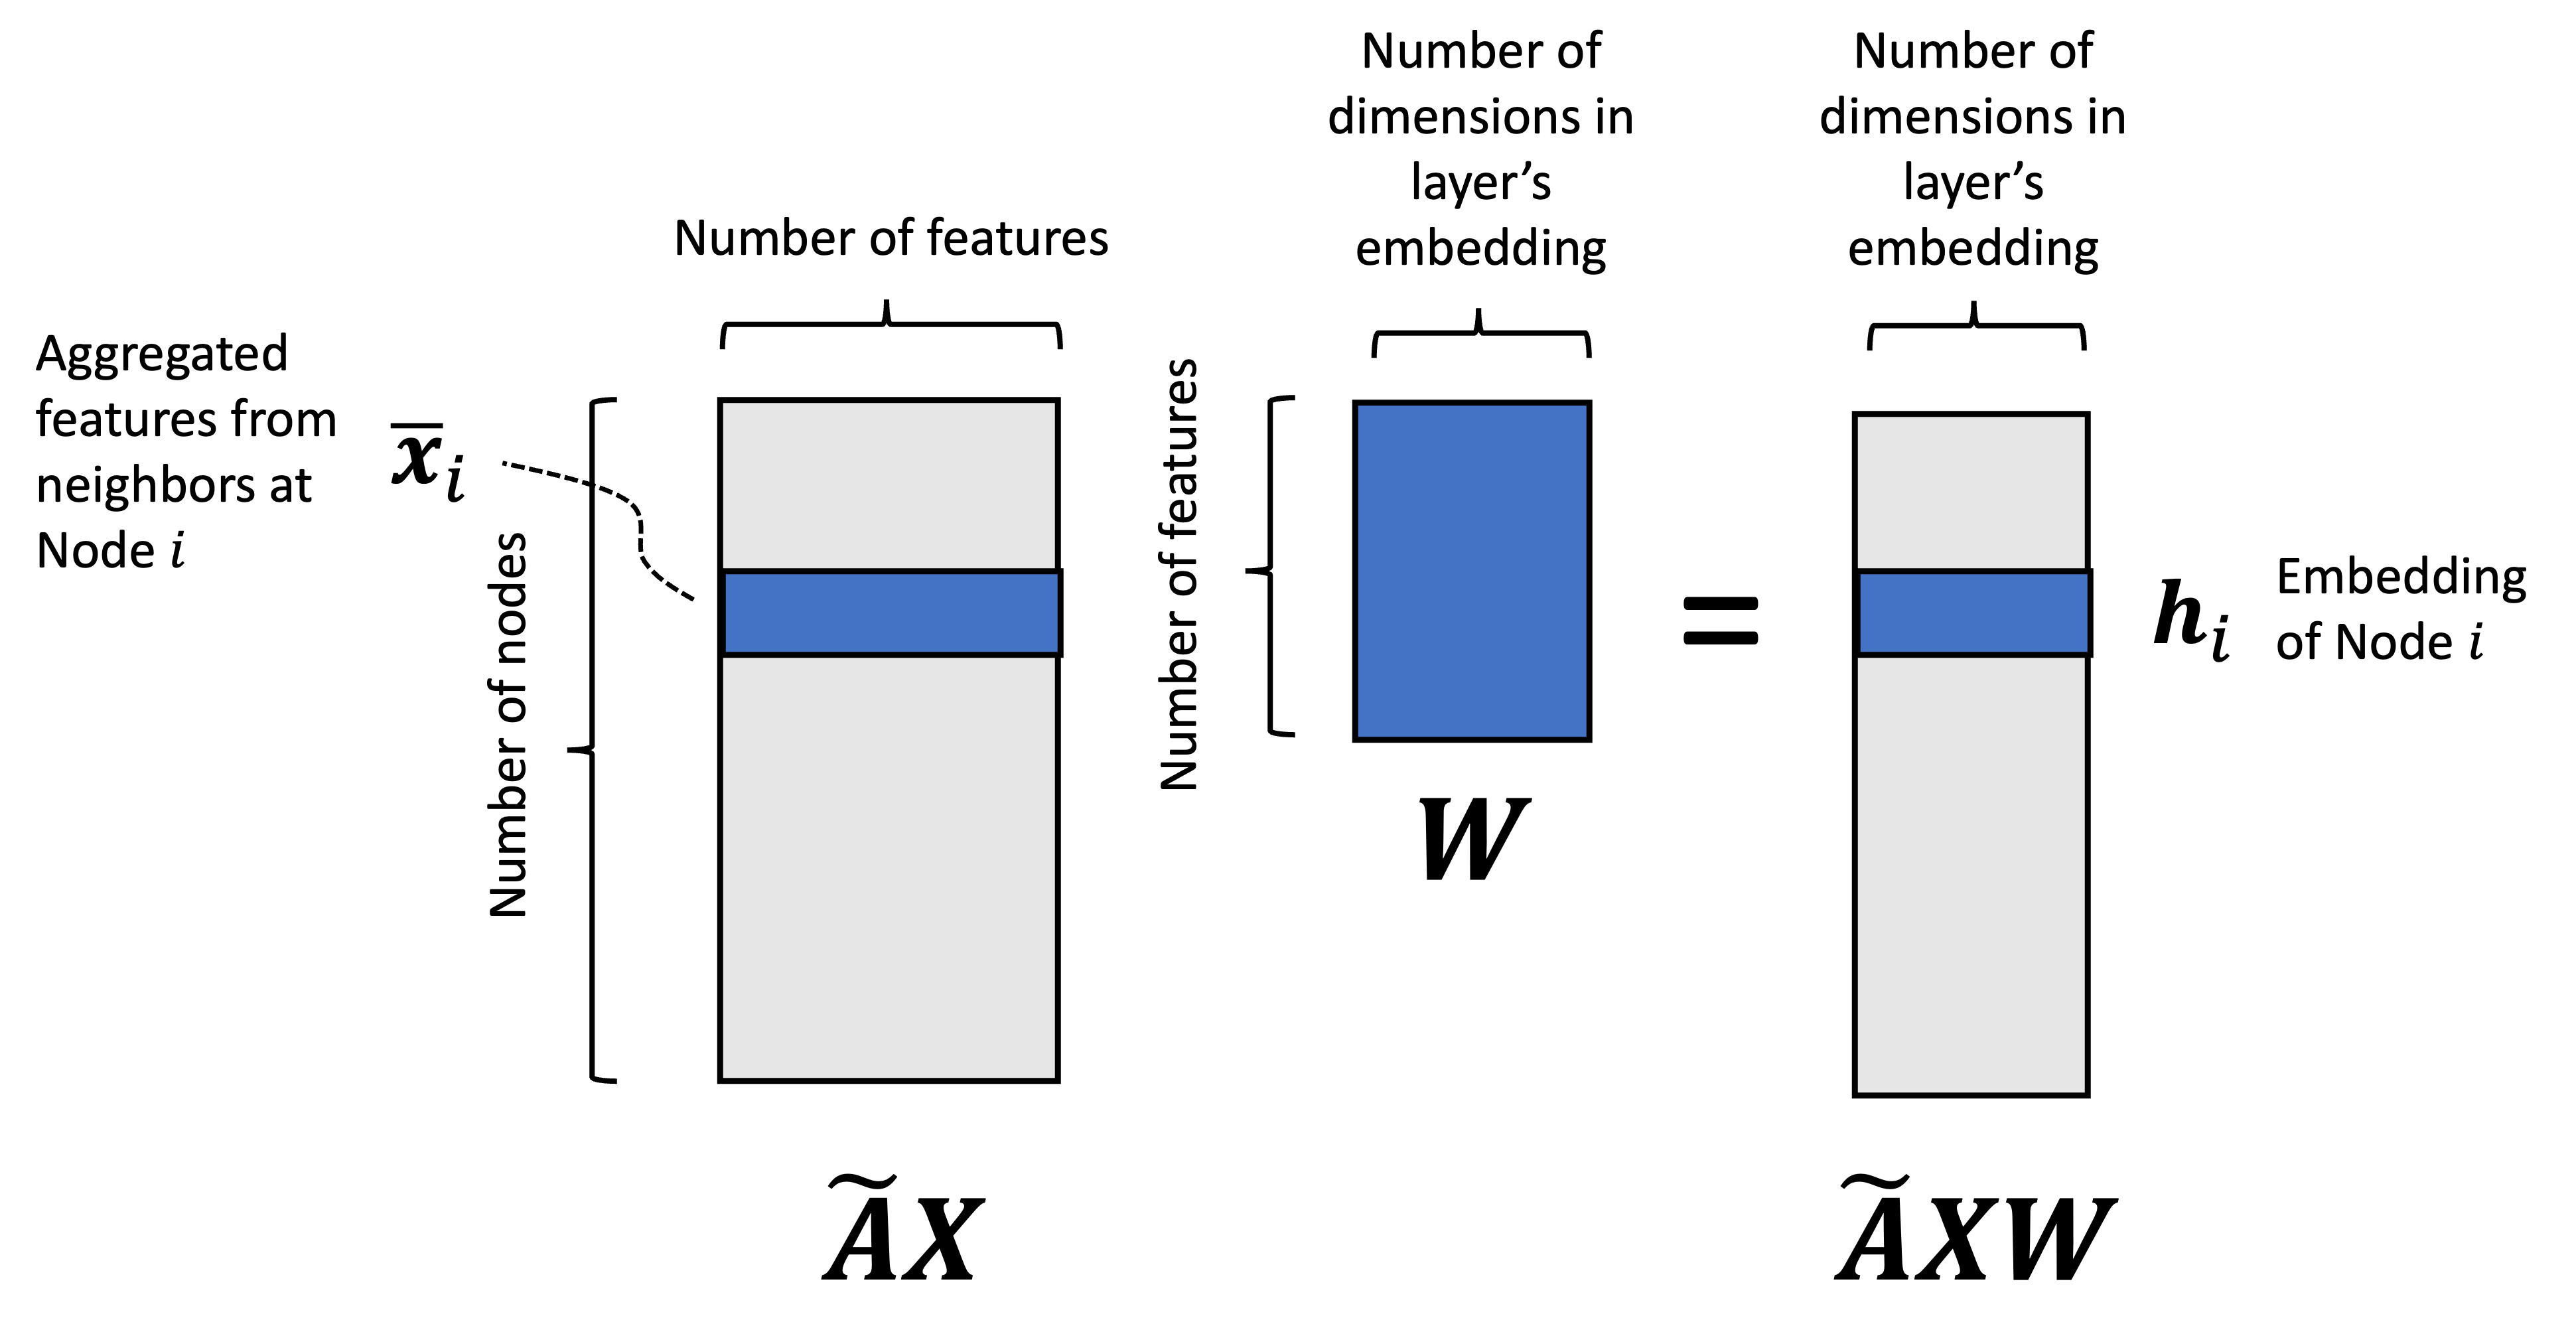

Визуализация процесса графовой свертки:

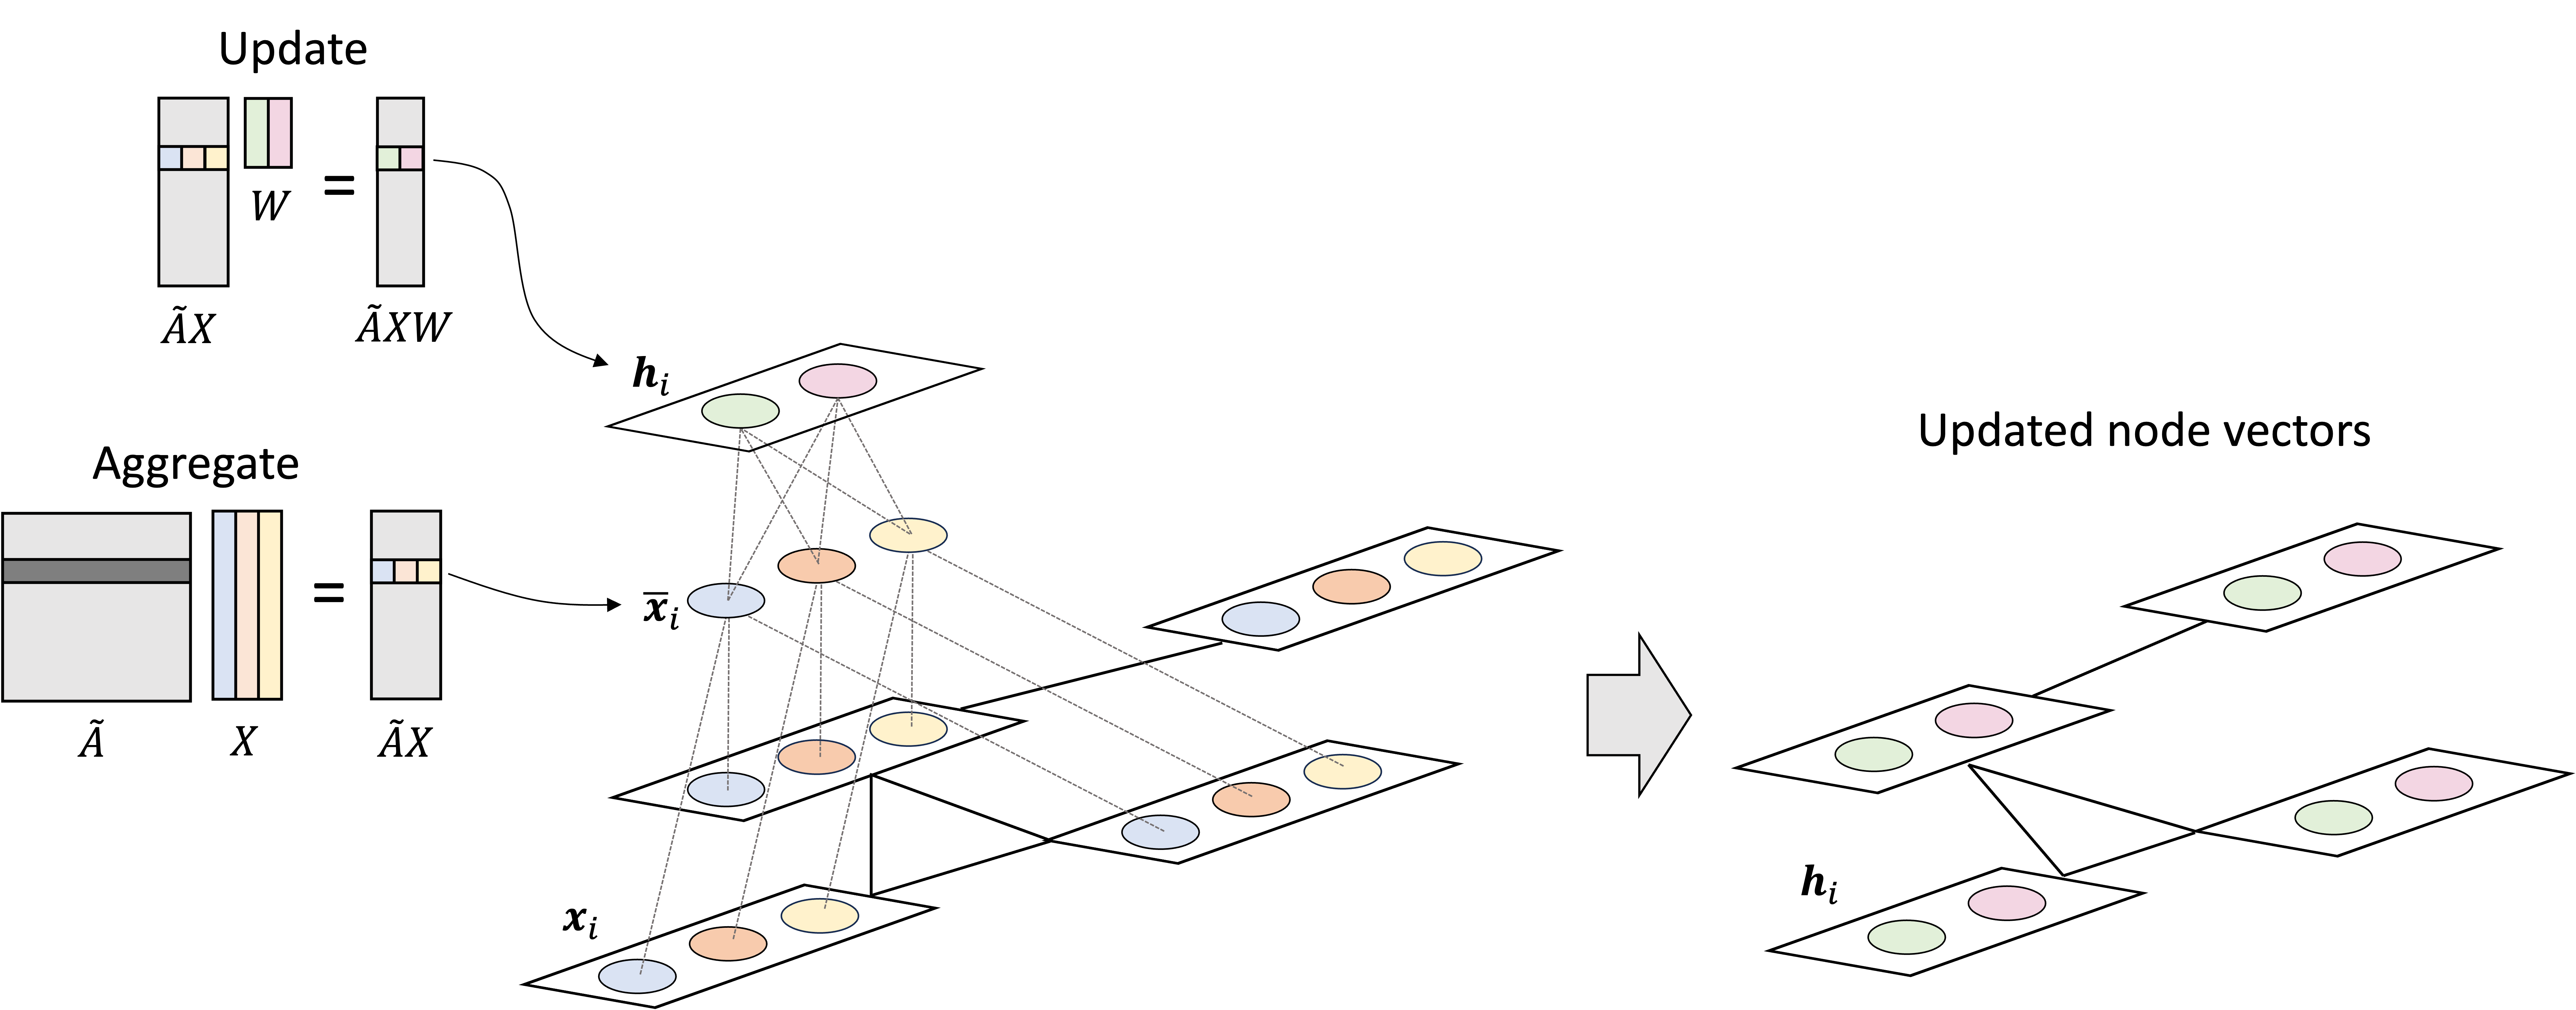

Если слоев несколько, то выходные эмбеддинги $i$-го слоя $h^{(i)}$ являются входными эмбеддингами слоя $i+1$.

$$ H^{(1)} = f_{W_0}(X, A), $$
$$ H^{(2)} = f_{W_1}(H^{(1)}, A). $$

In [ ]:
# Импортируем библиотеку для работы с графами и не только
import random
import networkx as nx
import numpy as np
from scipy.linalg import fractional_matrix_power

%matplotlib inline
import matplotlib.pyplot as plt

## Пример 0.

Попробуем, как это работает.

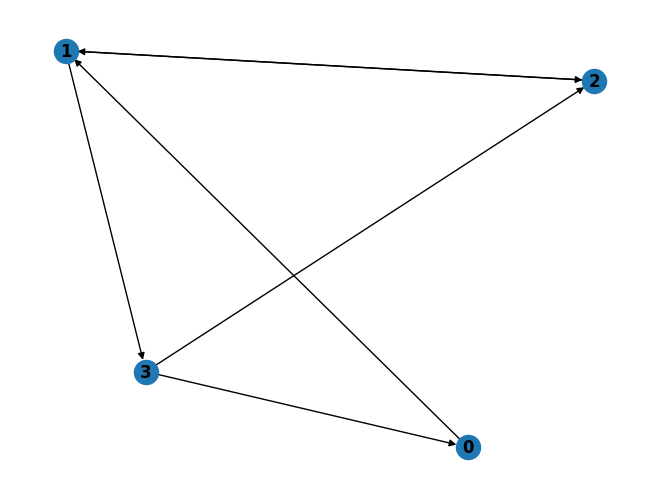

In [ ]:
# Создадим граф
G = nx.DiGraph()
G.add_edges_from([(0, 1), (1, 2), (1, 3), (2, 1),  (3, 2), (3, 0)])

nx.draw(G, with_labels=True, font_weight='bold')
plt.show()

In [ ]:
# Матрица смежности
A = nx.adjacency_matrix(G).toarray()
A

array([[0, 1, 1, 1, 0, 0, 0, 0, 0, 0],
       [1, 0, 0, 0, 1, 1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 1, 1, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 1, 1],
       [0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 1, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 1, 0, 0, 0, 0, 1, 0]])

Создадим начальные признаки, основываясь на номере узла.

In [ ]:
X = np.array([
            [i, -i]
            for i in range(A.shape[0])
        ], dtype=float)
X

array([[ 0.,  0.],
       [ 1., -1.],
       [ 2., -2.],
       [ 3., -3.]])

Сбор "сообщений" от соседей: перемножение матриц $A$ и $X$.

In [ ]:
A.dot(X)

array([[ 1., -1.],
       [ 5., -5.],
       [ 1., -1.],
       [ 2., -2.]])

Но непосредственный вклад узла не учитывается. Добавим в граф петли: вместо $A ←A + I$.

In [ ]:
# Единичная  матрица
I = np.array(np.eye(A.shape[0]))

# A <- A + I
A_hat = A + I

# Перемножим
A_hat.dot(X)

array([[ 1., -1.],
       [ 6., -6.],
       [ 3., -3.],
       [ 5., -5.]])

In [ ]:
A_hat

array([[1., 1., 0., 0.],
       [0., 1., 1., 1.],
       [0., 1., 1., 0.],
       [1., 0., 1., 1.]])

In [ ]:
# Осреднение по соседям D^{-1}AX
# Диагональная матрица степеней (с учетом петель)
D_hat = np.diag(np.array(np.sum(A_hat, axis=0)))
D_hat

array([[2., 0., 0., 0.],
       [0., 3., 0., 0.],
       [0., 0., 3., 0.],
       [0., 0., 0., 2.]])

In [ ]:
np.linalg.inv(D_hat).dot(A_hat)

array([[0.5       , 0.5       , 0.        , 0.        ],
       [0.        , 0.33333333, 0.33333333, 0.33333333],
       [0.        , 0.33333333, 0.33333333, 0.        ],
       [0.5       , 0.        , 0.5       , 0.5       ]])

Зададим веса

In [ ]:
W = np.array([
             [1, -1],
             [-1, 1]
         ])

In [ ]:
# Начальные признаки превращаются в ...
np.linalg.inv(D_hat).dot(A_hat).dot(X).dot(W)

array([[ 1., -1.],
       [ 4., -4.],
       [ 2., -2.],
       [ 5., -5.]])

В качестве функции активации возьмем
[ReLU](https://en.wikipedia.org/wiki/Rectifier_(neural_networks))

$$f(x)=x^{+}=\max(0,x)={\cfrac {x+|x|}{2}}.$$

In [ ]:
# ReLU
def relu(x):
  x[x<0] = 0
  return x

In [ ]:
# Получили новые признаки
relu(np.linalg.inv(D_hat).dot(A_hat).dot(X).dot(W))

array([[1., 0.],
       [4., 0.],
       [2., 0.],
       [5., 0.]])

# Пример 1.


 Graph Nodes: [(0, {'name': 0}), (1, {'name': 1}), (2, {'name': 2}), (3, {'name': 3}), (4, {'name': 4}), (5, {'name': 5})]


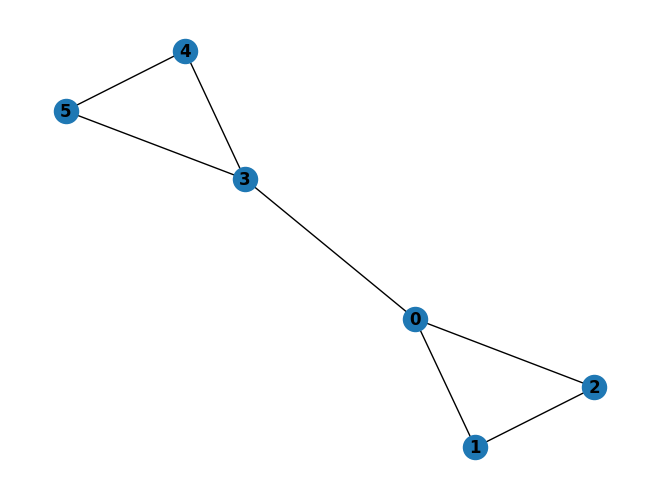

In [ ]:
# Создадим другой граф
G = nx.Graph(name='G')

for i in range(6):
    G.add_node(i, name=i)

edges = [(0, 1), (0, 2), (1, 2), (0, 3), (3, 4), (3, 5), (4, 5)]
G.add_edges_from(edges)

print('\n Graph Nodes: {0}'.format(G.nodes.data()))

nx.draw(G, with_labels=True, font_weight='bold')
plt.show()

Матрица смежности

In [ ]:
# Матрица атрибутов (матрица смежности, если атрибутов нет)
nx.attr_matrix(G, node_attr='name')

KeyError: 'name'

In [ ]:
# Матрица смежности (A) and вектор признаков (X) as numpy array
# Начальные признаки - номер узла
A = np.array(nx.attr_matrix(G, node_attr='name')[0])
X = np.array(nx.attr_matrix(G, node_attr='name')[1])
X = np.expand_dims(X,axis=1)

print('Размерность A: {0}'.format(A.shape))
print('\n Размерность X: {0}'.format(X.shape))
print('\n Матрица смежности (A):\n{0}'.format(A))
print('\n Признаки (начальные) (X):\n{0}'.format(X))

Размерность A: (6, 6)

 Размерность X: (6, 1)

 Матрица смежности (A):
[[0. 1. 1. 1. 0. 0.]
 [1. 0. 1. 0. 0. 0.]
 [1. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 0. 1.]
 [0. 0. 0. 1. 1. 0.]]

 Признаки (начальные) (X):
[[0]
 [1]
 [2]
 [3]
 [4]
 [5]]


In [ ]:
# Произведение A.X
AX = np.dot(A,X)
print('Произведение A.X (AX):\n{0}'.format(AX))

Произведение A.X (AX):
[[6.]
 [2.]
 [1.]
 [9.]
 [8.]
 [7.]]


Добавим в граф петли для учёта вклада не только соседей, но и самого узла $v$.

In [ ]:
G_self_loops = G.copy()

self_loops = []
for i in range(G.number_of_nodes()):
    self_loops.append((i,i))

G_self_loops.add_edges_from(self_loops)

# Проверяем, добавились ли петли
print('Граф G с петлями:\n{0}'.format(G_self_loops.edges))

# Матрица смежности нового графа
A_hat = np.array(nx.attr_matrix(G_self_loops, node_attr='name')[0])
print('\n Матрица смежности нового графа (A_hat):\n{0}'.format(A_hat))

# Снова перемножим матрицы
AX = np.dot(A_hat,X)
print('Произведение A_hat.X (AX):\n{0}'.format(AX))

Граф G с петлями:
[(0, 1), (0, 2), (0, 3), (0, 0), (1, 2), (1, 1), (2, 2), (3, 4), (3, 5), (3, 3), (4, 5), (4, 4), (5, 5)]

 Матрица смежности нового графа (A_hat):
[[1. 1. 1. 1. 0. 0.]
 [1. 1. 1. 0. 0. 0.]
 [1. 1. 1. 0. 0. 0.]
 [1. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]]
Произведение A_hat.X (AX):
[[ 6.]
 [ 3.]
 [ 3.]
 [12.]
 [12.]
 [12.]]


In [ ]:
# Вектор степеней графа с петлями (A+I)
Deg_Mat = G_self_loops.degree()
print('Вектор степеней графа с петлями G (D): {0}'.format(Deg_Mat))

# Преобразуем в матрицу N x N, где N число узлов
D = np.diag([deg for (n,deg) in list(Deg_Mat)])
print('\n Матрица степеней графа с петлями (D):\n{0}'.format(D))

# Обратная матрица (D)
D_inv = np.linalg.inv(D)
print('\n Обратная матрица D:\n{0}'.format(D_inv))

# Перемножаем D^{-1} и AX
DAX = np.dot(D_inv,AX)
print('\n DAX:\n{0}'.format(DAX))

Вектор степеней графа с петлями G (D): [(0, 5), (1, 4), (2, 4), (3, 5), (4, 4), (5, 4)]

 Матрица степеней графа с петлями (D):
[[5 0 0 0 0 0]
 [0 4 0 0 0 0]
 [0 0 4 0 0 0]
 [0 0 0 5 0 0]
 [0 0 0 0 4 0]
 [0 0 0 0 0 4]]

 Обратная матрица D:
[[0.2  0.   0.   0.   0.   0.  ]
 [0.   0.25 0.   0.   0.   0.  ]
 [0.   0.   0.25 0.   0.   0.  ]
 [0.   0.   0.   0.2  0.   0.  ]
 [0.   0.   0.   0.   0.25 0.  ]
 [0.   0.   0.   0.   0.   0.25]]

 DAX:
[[1.2 ]
 [0.75]
 [0.75]
 [2.4 ]
 [3.  ]
 [3.  ]]


## Перенормировка

"Сообщения" от соседей могут иметь разный вклад в итоговый вектор признаков, в том числе в зависимости от выбранного нормирования.

При нормировании $D^{-1}\hat{A}$ влияние $i$-то узла на $j$ выше, если у $i$ мало соседей, и меньше, если соседей много.

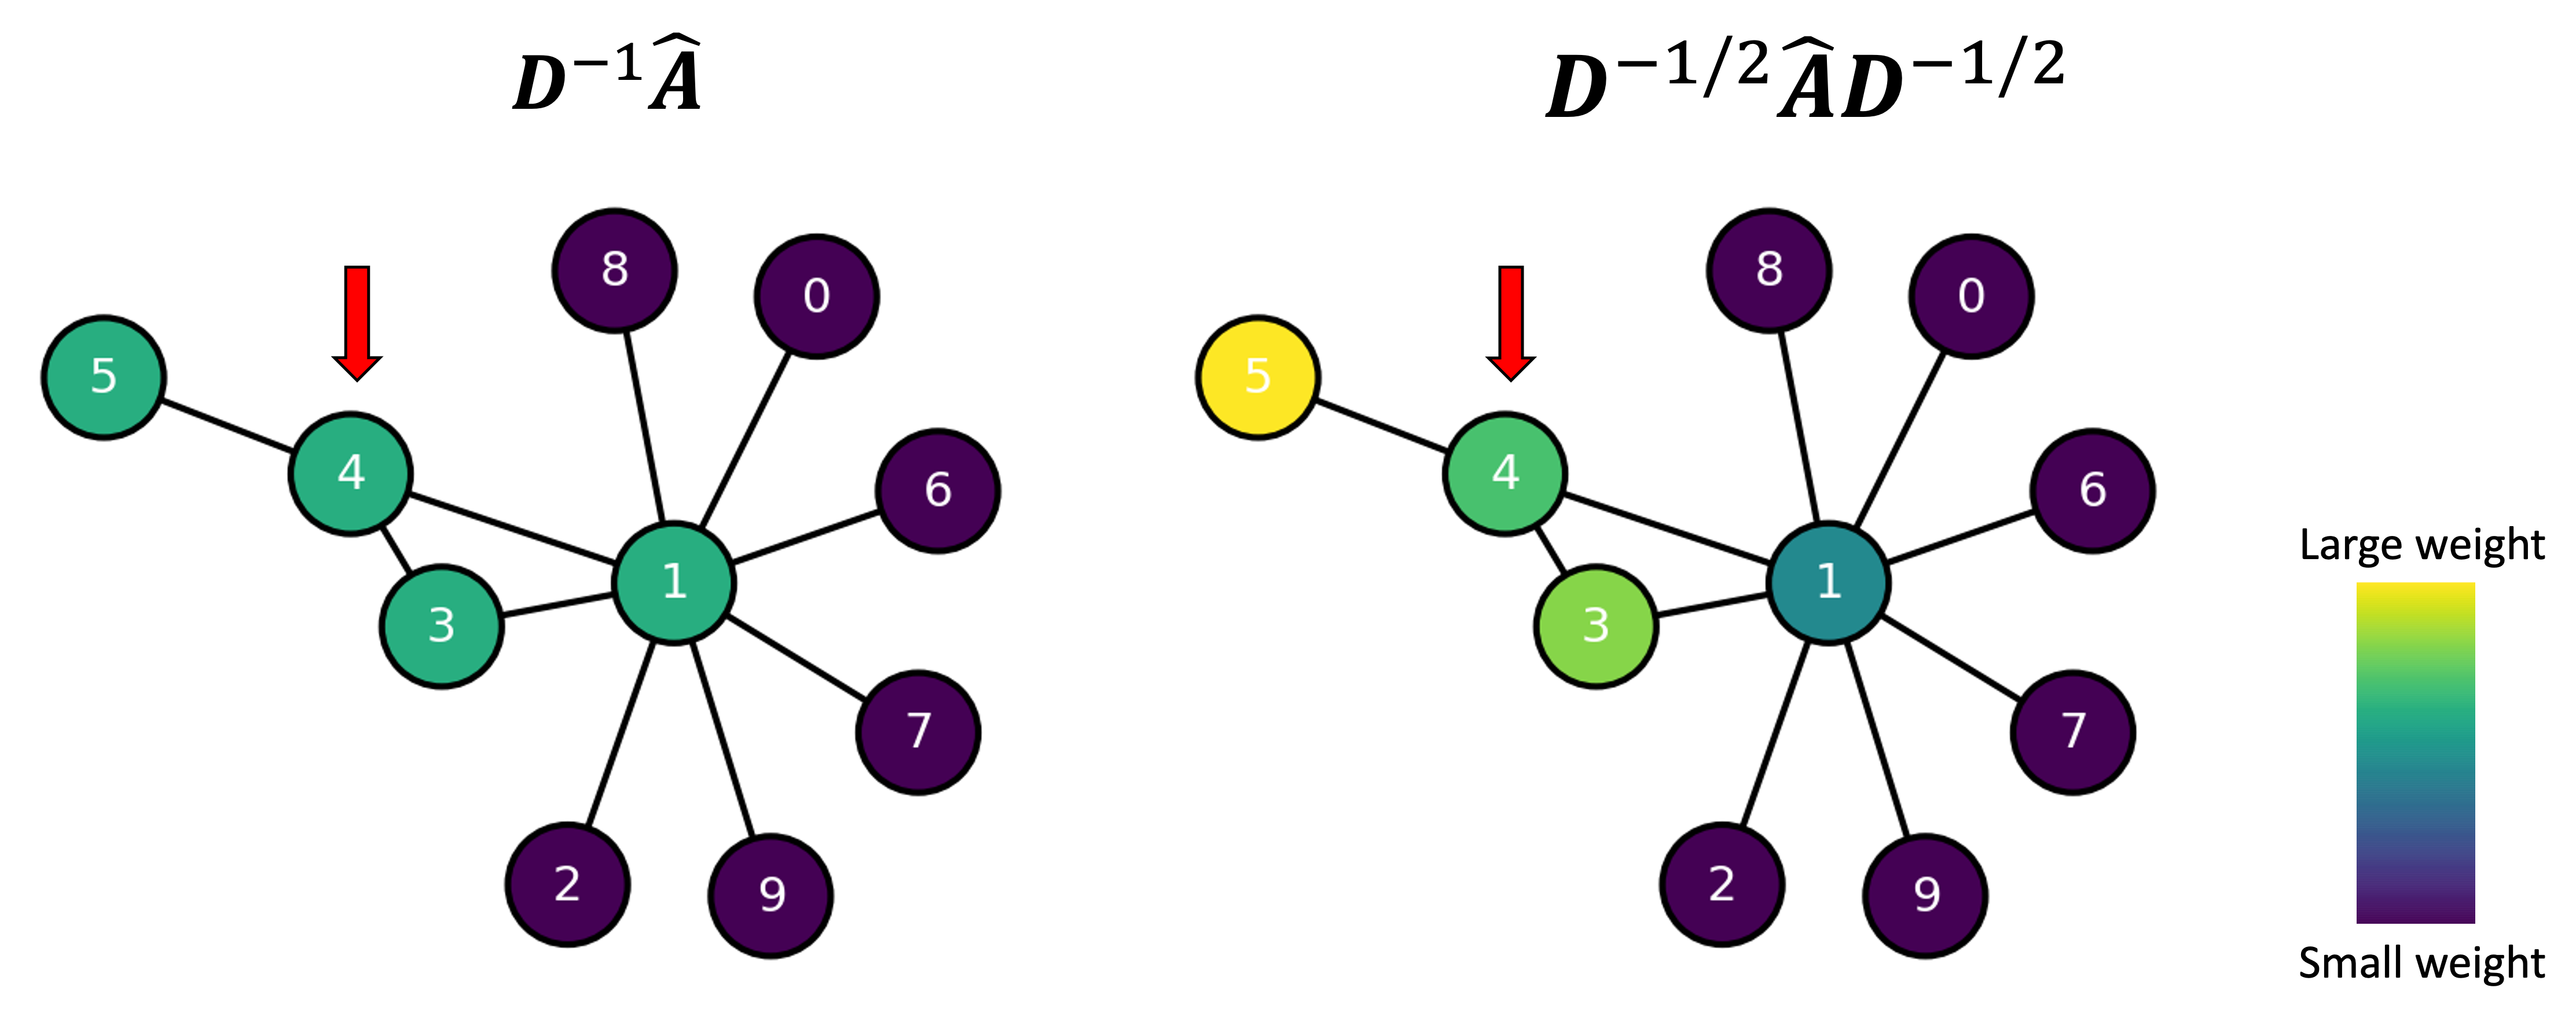

В [Kipf and Welling (2017)](https://arxiv.org/abs/1609.02907) вместо $\hat{A} = D^{-1} (A+I)$ используется симметрическую нормализацию $$\tilde{A} = D^{-1/2} (A+I) D^{-1/2}.$$

Симметричесная нормализация позволяет учесть, как много соседей есть у соседей узла $i$.

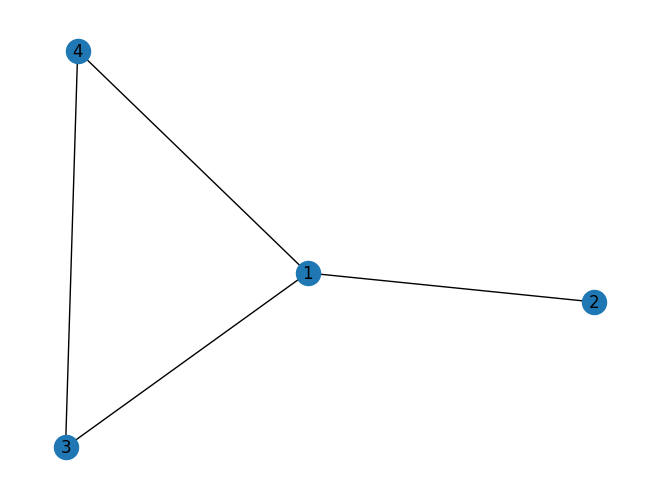

In [ ]:
# Граф
G2 = nx.Graph()
G2.add_edges_from([(1, 2), (1, 3), (1, 4), (3, 4)])
nx.draw(G2, with_labels = True)

In [ ]:
# Матрица смежности
A2 = nx.adjacency_matrix(G2).toarray()

# Матрица смежности с учетом петель
A2_hat = A2 + np.identity(4)

In [ ]:
# Диагональная матрица степеней
G2_node_degrees = [degree[1] for degree in G2.degree()]
D2 = np.diag(G2_node_degrees)
D2

array([[3, 0, 0, 0],
       [0, 1, 0, 0],
       [0, 0, 2, 0],
       [0, 0, 0, 2]])

In [ ]:
# Диагональная матрица степеней (с учетом петель)
D2_hat = D2 + np.identity(4)
D2_hat

array([[4., 0., 0., 0.],
       [0., 2., 0., 0.],
       [0., 0., 3., 0.],
       [0., 0., 0., 3.]])

*   $\tilde{D}^{-1}\tilde{A} X W$ - нормируем строки матрицы признаков $X$

In [ ]:
print(np.linalg.inv(D2_hat) @ A2_hat)

[[0.25       0.25       0.25       0.25      ]
 [0.5        0.5        0.         0.        ]
 [0.33333333 0.         0.33333333 0.33333333]
 [0.33333333 0.         0.33333333 0.33333333]]


*   $\tilde{A}\tilde{D}^{-1} X W$ - нормируем столбцы матрицы признаков $X$

In [ ]:
print(A2_hat @ np.linalg.inv(D2_hat))

[[0.25       0.5        0.33333333 0.33333333]
 [0.25       0.5        0.         0.        ]
 [0.25       0.         0.33333333 0.33333333]
 [0.25       0.         0.33333333 0.33333333]]


* $\hat{D}^{-1/2} \hat{A} \hat{D}^{-1/2}$ - симметрическая нормализация.



In [ ]:
print(np.linalg.inv(np.sqrt(D2_hat)) @ A2_hat @ np.linalg.inv(np.sqrt(D2_hat)))

[[0.25       0.35355339 0.28867513 0.28867513]
 [0.35355339 0.5        0.         0.        ]
 [0.28867513 0.         0.33333333 0.33333333]
 [0.28867513 0.         0.33333333 0.33333333]]


Вернемся к примеру 1 и перенормируем матрицу смежности.

In [ ]:
# Перенормируем матрицу смежности
D_half_norm = fractional_matrix_power(D, -0.5)
DADX = D_half_norm.dot(A_hat).dot(D_half_norm).dot(X)
print('DADX:\n{0}'.format(DADX))

DADX:
[[1.27082039]
 [0.75      ]
 [0.75      ]
 [2.61246118]
 [2.92082039]
 [2.92082039]]


Строим двухслойная сеть с прямым распространением. Четыре нейрона в первом слое. Два нейрона на выходе (два измерения). Функция активации - Relu.

In [ ]:
# Задаем веса
np.random.seed(77777)
n_h = 4 # число нейронов в скрытом слое
n_y = 2 # число нейронов в скрытом слое
W0 = np.random.randn(X.shape[1],n_h) * 0.01 # случайные веса
W1 = np.random.randn(n_h,n_y) * 0.01

# Функция активации
def relu(x):
    return np.maximum(0, x)

# Слой GCN
def gcn(A, H, W):
    I = np.identity(A.shape[0]) # единичная матрица
    A_hat = A + I # добавили петли
    D = np.diag(np.sum(A_hat, axis=0)) # матрица степеней
    D_half_norm = fractional_matrix_power(D, -0.5) # нормализация
    eq = D_half_norm.dot(A_hat).dot(D_half_norm).dot(H).dot(W)
    return relu(eq)

# Прямой проход (forward propagation)
H1 = gcn(A, X, W0)
H2 = gcn(A, H1, W1)
print('Финальные признаки:\n{0}'.format(H2))

Финальные признаки:
[[0.00027758 0.        ]
 [0.00017298 0.        ]
 [0.00017298 0.        ]
 [0.00053017 0.        ]
 [0.00054097 0.        ]
 [0.00054097 0.        ]]


Графическое представление признаков

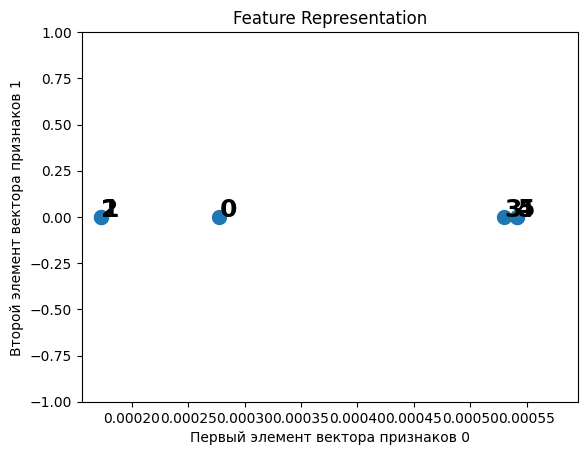

In [ ]:
def plot_features(H2):
    #Plot the features representation
    x = H2[:,0]
    y = H2[:,1]

    size = 100

    plt.scatter(x,y,size)
    plt.xlim([np.min(x)*0.9, np.max(x)*1.1])
    plt.ylim([-1, 1])
    plt.xlabel('Первый элемент вектора признаков 0')
    plt.ylabel('Второй элемент вектора признаков 1')
    plt.title('Feature Representation')

    for i,row in enumerate(H2):
        str = "{}".format(i)
        plt.annotate(str, (row[0],row[1]),fontsize=18, fontweight='bold')

    plt.show()


plot_features(H2)

# Задание 1.

С помощью 2-х слойной сверточной сети (GCN) вычислите признаки для узлов заданного графа.  

* Начальные атрибуты - номера узлов.
* Начальные атрибуты задаются единичной матрицей.



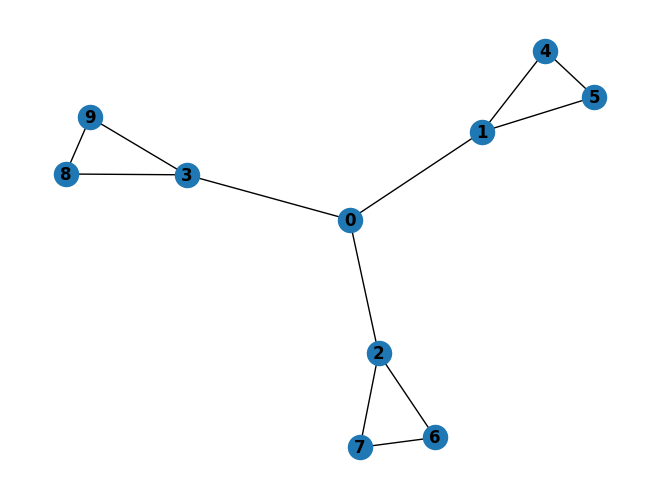


 Graph Nodes: [(0, {'name': 0}), (1, {'name': 1}), (2, {'name': 2}), (3, {'name': 3}), (4, {'name': 4}), (5, {'name': 5}), (7, {}), (6, {}), (9, {}), (8, {})]


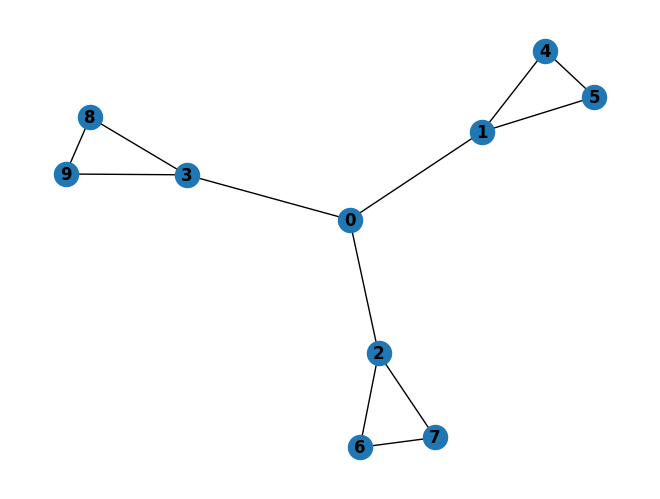

In [ ]:
# Создадим другой граф
G = nx.Graph(name='G')

for i in range(6):
    G.add_node(i, name=i)

edges = [(0, 1), (0, 2), (0 ,3), (1, 4), (1,5), (4,5), (2,7), (2,6), (6,7), (3,9), (3, 8), (8, 9)]
G.add_edges_from(edges)

print('\n Graph Nodes: {0}'.format(G.nodes.data()))

nx.draw(G, with_labels=True, font_weight='bold')
plt.show()

В качестве функции активации возьмем
[ReLU](https://en.wikipedia.org/wiki/Rectifier_(neural_networks))

$$f(x)=x^{+}=\max(0,x)={\cfrac {x+|x|}{2}}.$$

In [ ]:
# ReLU
def relu(x):
  x[x<0] = 0
  return x

In [ ]:
X_1 = np.ones((A.shape[0], 2))
X_1

array([[1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.],
       [1., 1.]])

In [ ]:
A = nx.adjacency_matrix(G).toarray()

# Начальные признаки: номера узлов, преобразованные в векторы
X = np.array([[i, -i] for i in range(A.shape[0])], dtype=float)
# Начальные признаки — единичная матрица (по одному признаку на узел)
X_1 = np.ones((A.shape[0], 1))

I = np.eye(A.shape[0])
A_hat = A + I

D_hat = np.diag(np.sum(A_hat, axis=1))

D_inv_sqrt = np.linalg.inv(np.sqrt(D_hat))
A_norm = D_inv_sqrt @ A_hat @ D_inv_sqrt

W = np.array([[1, -1], [-1, 1]])

H1 = relu(A_norm @ X @ W) #(10, 10) @ (10, 2) @ (2, 2) = (10, 2)
H2 = relu(A_norm @ H1 @ W) #(10, 10) @ (10, 2) @ (2, 2) = (10, 2)

print('Признаки после 2-х слоёв GCN:')
print(H2)

W_1 = np.array([[1, -1]])
H1_1 = relu(A_norm @ X_1 @ W_1)  #(10, 10) @ (10, 1) @ (1, 2) = (10, 2)
H2_1 = relu(A_norm @ H1_1 ) #(10, 10) @ (10, 2)

print('Признаки после 2-х слоёв GCN:')
print(H2_1)



Признаки после 2-х слоёв GCN:
[[ 7.12916512  0.        ]
 [ 5.97147305  0.        ]
 [ 8.54675737  0.        ]
 [11.12204169  0.        ]
 [ 6.02923775  0.        ]
 [ 6.02923775  0.        ]
 [ 9.00291994  0.        ]
 [ 9.00291994  0.        ]
 [11.97660213  0.        ]
 [11.97660213  0.        ]]
Признаки после 2-х слоёв GCN:
[[1.0580127  0.        ]
 [1.07090441 0.        ]
 [1.07090441 0.        ]
 [1.07090441 0.        ]
 [0.94789877 0.        ]
 [0.94789877 0.        ]
 [0.94789877 0.        ]
 [0.94789877 0.        ]
 [0.94789877 0.        ]
 [0.94789877 0.        ]]


Финальные признаки:
 [[0.00015151 0.        ]
 [0.00015498 0.        ]
 [0.00015498 0.        ]
 [0.00015498 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]]


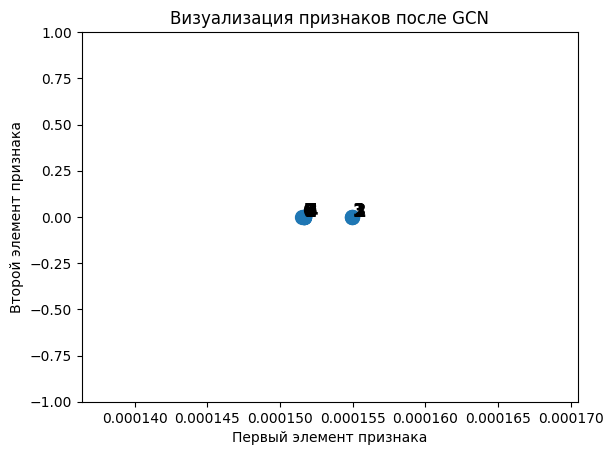

Финальные признаки:
 [[0.00015151 0.        ]
 [0.00015498 0.        ]
 [0.00015498 0.        ]
 [0.00015498 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]
 [0.00015164 0.        ]]


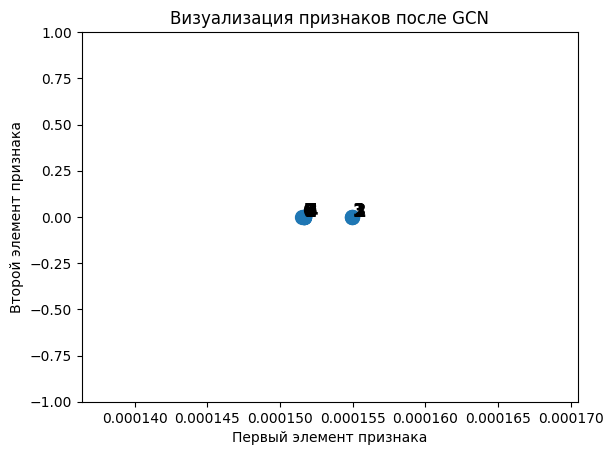

In [ ]:
# Матрица смежности
A = nx.adjacency_matrix(G).toarray()
A_hat = A + np.eye(10)

# Степень узлов
degrees = np.sum(A_hat, axis=1)
D = np.diag(degrees)

D_half_inv = fractional_matrix_power(D, -0.5)
A_norm = D_half_inv @ A_hat @ D_half_inv

# Начальные признаки (единичная матрица)
X = np.ones((A.shape[0], 1))

np.random.seed(77777)
n_h = 4  # число нейронов в скрытом слое
n_y = 2  # число нейронов на выходе

W0 = np.random.randn(1, n_h) * 0.01
W1 = np.random.randn(n_h, n_y) * 0.01

def relu(x):
    return np.maximum(0, x)

def gcn(A_norm, H, W):
    I = np.eye(A_norm.shape[0])
    A_hat = A_norm + I
    D = np.diag(np.sum(A_hat, axis=1))
    D_half_inv = fractional_matrix_power(D, -0.5)
    A_norm_layer = D_half_inv @ A_hat @ D_half_inv
    return relu(A_norm_layer @ H @ W)

H1 = gcn(A_norm, X, W0)
H2 = gcn(A_norm, H1, W1)

print('Финальные признаки:\n', H2)

def plot_features(H):
    x = H[:, 0]
    y = H[:, 1]
    plt.scatter(x, y, s=100)
    plt.xlim([np.min(x) * 0.9, np.max(x) * 1.1])
    plt.ylim([-1, 1])
    plt.xlabel('Первый элемент признака')
    plt.ylabel('Второй элемент признака')
    plt.title('Визуализация признаков после GCN')
    for i, row in enumerate(H):
        plt.annotate(str(i), (row[0], row[1]), fontsize=14, fontweight='bold')
    plt.show()

plot_features(H2)


# Начальные признаки — номера узлов
X_2 = np.array([[i] for i in range(10)])  # (10, 1)

H1_2 = gcn(A_norm, X_2, W0)
H2_2 = gcn(A_norm, H1, W1)

print('Финальные признаки:\n', H2)
plot_features(H2_2)